In [1]:
import pandas as pd
import os
from sqlalchemy import create_engine
from dotenv import load_dotenv
import matplotlib.pyplot as plt
import seaborn as sns

### Loading Claims Dataset

In [2]:
load_dotenv()
DATABASE_URL = f"postgresql://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}@{os.getenv('DB_HOST')}:{os.getenv('DB_PORT')}/{os.getenv('DB_NAME')}"
engine= create_engine(DATABASE_URL)

In [3]:
claims_df= pd.read_sql("Select * from Claims", engine)

print(claims_df.shape)

(250000, 38)


In [4]:
claims_df.head()

,id,record_id,customer_age,city,state,city_tier,city_risk_score,vehicle_type,vehicle_make,vehicle_model,...,incident_time_of_day,incident_type,damage_type,damage_severity_score,num_parts_affected,affected_parts,claim_amount,approval_probability,claim_approved,created_at
0,9d373393-159f-4694-a85e-c3d11e2a20b3,8c72dd60,50,Ghaziabad,Uttar Pradesh,2,1.25,bike,Ampere,Primus,...,Evening,Fire,bumper damage,2,1,Handlebar,5107.0,0.8865,True,2026-07-18 12:03:21.030528
1,f04a80a8-3bbc-4343-860e-0ddf52740ec5,9f28d23f,19,Sikar,Rajasthan,3,0.85,bike,Kawasaki,Ninja 1000SX,...,Evening,Flooding,dent,3,2,"Exhaust, Fuel tank",21482.0,0.8586,True,2026-07-18 12:03:21.030528
2,46490252-7f81-459c-82a4-498f87210daa,95540861,28,Bokaro,Jharkhand,3,0.88,bike,Bounce,Infinity E1,...,Afternoon,Vandalism,bumper damage,3,1,Seat,7832.0,0.9262,True,2026-07-18 12:03:21.030528
3,6dc6570d-86a0-4942-b303-bc356289c989,b7e17e01,44,Belgaum,Karnataka,3,0.90,bike,Honda,Gold Wing,...,Evening,Flooding,crack,2,1,Front wheel,94459.0,0.7198,True,2026-07-18 12:03:21.030528
4,b6127814-388a-418d-a18e-7eb2a1244714,69ce9920,51,Vadodara,Gujarat,2,1.12,bike,Bounce,Infinity E1,...,Afternoon,Fire,windshield damage,2,2,"Front wheel, Footrest",8291.0,0.7477,True,2026-07-18 12:03:21.030528


In [5]:
claims_df.groupby('claim_approved')['claim_amount'].describe()

,count,mean,std,min,25%,50%,75%,max
claim_approved,,,,,,,,
False,33029.0,770802.390142,1.527246e+06,1025.0,53788.0,240330.0,717139.0,22508201.0
True,216971.0,226381.478843,6.517680e+05,712.0,12955.0,45406.0,167392.0,21343906.0


In [6]:
claims_df[['claim_amount', 'approval_probability', 'claim_approved']].corr()

,claim_amount,approval_probability,claim_approved
claim_amount,1.000000,-0.232836,-0.218659
approval_probability,-0.232836,1.000000,0.737108
claim_approved,-0.218659,0.737108,1.000000


In [7]:
claims_df[["manufacturing_year", "vehicle_age_years"]].corr()

,manufacturing_year,vehicle_age_years
manufacturing_year,1.0,-1.0
vehicle_age_years,-1.0,1.0


In [8]:
claims_df.columns

Index(['id', 'record_id', 'customer_age', 'city', 'state', 'city_tier',
       'city_risk_score', 'vehicle_type', 'vehicle_make', 'vehicle_model',
       'segment', 'engine_cc', 'manufacturing_year', 'vehicle_age_years',
       'idv', 'policy_type', 'policy_age_months', 'annual_premium_paid',
       'previous_claims_count', 'ncb_at_claim_percent', 'zero_dep_addon',
       'engine_protection_addon', 'usage_type', 'rider_experience_years',
       'helmet_worn', 'incident_date', 'incident_day_of_week',
       'incident_month', 'incident_time_of_day', 'incident_type',
       'damage_type', 'damage_severity_score', 'num_parts_affected',
       'affected_parts', 'claim_amount', 'approval_probability',
       'claim_approved', 'created_at'],
      dtype='object')

In [9]:
claims_df['incident_year'] = pd.to_datetime(claims_df['incident_date']).dt.year

In [10]:
claims_df= claims_df.drop(columns=["id", "record_id", "created_at", "manufacturing_year", "incident_date"], axis=1)

In [11]:
claims_df.columns

Index(['customer_age', 'city', 'state', 'city_tier', 'city_risk_score',
       'vehicle_type', 'vehicle_make', 'vehicle_model', 'segment', 'engine_cc',
       'vehicle_age_years', 'idv', 'policy_type', 'policy_age_months',
       'annual_premium_paid', 'previous_claims_count', 'ncb_at_claim_percent',
       'zero_dep_addon', 'engine_protection_addon', 'usage_type',
       'rider_experience_years', 'helmet_worn', 'incident_day_of_week',
       'incident_month', 'incident_time_of_day', 'incident_type',
       'damage_type', 'damage_severity_score', 'num_parts_affected',
       'affected_parts', 'claim_amount', 'approval_probability',
       'claim_approved', 'incident_year'],
      dtype='object')

In [12]:
claims_df.isna().sum()

customer_age                    0
city                            0
state                           0
city_tier                       0
city_risk_score                 0
vehicle_type                    0
vehicle_make                    0
vehicle_model                   0
segment                         0
engine_cc                       0
vehicle_age_years               0
idv                             0
policy_type                     0
policy_age_months               0
annual_premium_paid             0
previous_claims_count           0
ncb_at_claim_percent            0
zero_dep_addon                  0
engine_protection_addon    100000
usage_type                      0
rider_experience_years          0
helmet_worn                150000
incident_day_of_week            0
incident_month                  0
incident_time_of_day            0
incident_type                   0
damage_type                     0
damage_severity_score           0
num_parts_affected              0
affected_parts

In [13]:
claims_df["helmet_worn"].value_counts()

helmet_worn
True     70105
False    29895
Name: count, dtype: int64

In [14]:
claims_df.loc[claims_df['vehicle_type']== "car"]['helmet_worn'].isna().sum()

150000

In [15]:
claims_df.loc[(claims_df['vehicle_type']== "car") & (claims_df['helmet_worn'].isna()), "helmet_worn"] = "None"

In [16]:
claims_df['helmet_worn'].isna().sum()

0

In [17]:
claims_df.loc[claims_df['vehicle_type']== "car"]['helmet_worn'].isna().sum()

0

In [18]:
claims_df.loc[claims_df['vehicle_type']== "bike"]['engine_protection_addon'].isna().sum()

100000

In [19]:
claims_df['engine_protection_addon']= claims_df['engine_protection_addon'].fillna("Not available")

In [20]:
claims_df['engine_protection_addon'].isna().sum()

0

In [21]:
claims_df.duplicated().sum()

0

In [22]:
claims_df.head()

,customer_age,city,state,city_tier,city_risk_score,vehicle_type,vehicle_make,vehicle_model,segment,engine_cc,...,incident_time_of_day,incident_type,damage_type,damage_severity_score,num_parts_affected,affected_parts,claim_amount,approval_probability,claim_approved,incident_year
0,50,Ghaziabad,Uttar Pradesh,2,1.25,bike,Ampere,Primus,ev_scooter,0,...,Evening,Fire,bumper damage,2,1,Handlebar,5107.0,0.8865,True,2021
1,19,Sikar,Rajasthan,3,0.85,bike,Kawasaki,Ninja 1000SX,sport_tourer,1043,...,Evening,Flooding,dent,3,2,"Exhaust, Fuel tank",21482.0,0.8586,True,2024
2,28,Bokaro,Jharkhand,3,0.88,bike,Bounce,Infinity E1,ev_scooter,0,...,Afternoon,Vandalism,bumper damage,3,1,Seat,7832.0,0.9262,True,2024
3,44,Belgaum,Karnataka,3,0.90,bike,Honda,Gold Wing,touring,1833,...,Evening,Flooding,crack,2,1,Front wheel,94459.0,0.7198,True,2022
4,51,Vadodara,Gujarat,2,1.12,bike,Bounce,Infinity E1,ev_scooter,0,...,Afternoon,Fire,windshield damage,2,2,"Front wheel, Footrest",8291.0,0.7477,True,2024


In [23]:
claims_df['affected_parts']

0                                                 Handlebar
1                                        Exhaust, Fuel tank
2                                                      Seat
3                                               Front wheel
4                                     Front wheel, Footrest
                                ...                        
249995                                            Underbody
249996                                         Transmission
249997    Boot lid, Dashboard, Roof, Front bumper, Right...
249998             Rear windshield, Alloy wheels, Fuel tank
249999    Right taillight, Airbags, Alloy wheels, Left t...
Name: affected_parts, Length: 250000, dtype: object

In [24]:
claims_df['affected_parts']= claims_df['affected_parts'].str.split(',')

In [25]:
claims_df['affected_parts']=  claims_df['affected_parts'].apply(lambda x: [item.strip() for item in x])

In [26]:
claims_df['affected_parts']=  claims_df['affected_parts'].apply(lambda x: [item.lower() for item in x])

In [27]:
claims_df['affected_parts']

0                                               [handlebar]
1                                      [exhaust, fuel tank]
2                                                    [seat]
3                                             [front wheel]
4                                   [front wheel, footrest]
                                ...                        
249995                                          [underbody]
249996                                       [transmission]
249997    [boot lid, dashboard, roof, front bumper, righ...
249998           [rear windshield, alloy wheels, fuel tank]
249999    [right taillight, airbags, alloy wheels, left ...
Name: affected_parts, Length: 250000, dtype: object

In [28]:
# Splitting columns into Categorical , Numerical and Datetime

In [29]:
cat_cols_ohe= claims_df.select_dtypes(include='object').drop(columns= ['affected_parts'])

In [30]:
cat_cols_ohe

,city,state,vehicle_type,vehicle_make,vehicle_model,segment,policy_type,engine_protection_addon,usage_type,helmet_worn,incident_day_of_week,incident_time_of_day,incident_type,damage_type
0,Ghaziabad,Uttar Pradesh,bike,Ampere,Primus,ev_scooter,Third Party,Not available,Personal,False,Saturday,Evening,Fire,bumper damage
1,Sikar,Rajasthan,bike,Kawasaki,Ninja 1000SX,sport_tourer,Comprehensive,Not available,Personal,False,Monday,Evening,Flooding,dent
2,Bokaro,Jharkhand,bike,Bounce,Infinity E1,ev_scooter,Comprehensive,Not available,Delivery,True,Sunday,Afternoon,Vandalism,bumper damage
3,Belgaum,Karnataka,bike,Honda,Gold Wing,touring,Comprehensive,Not available,Personal,False,Thursday,Evening,Flooding,crack
4,Vadodara,Gujarat,bike,Bounce,Infinity E1,ev_scooter,Third Party,Not available,Personal,True,Sunday,Afternoon,Fire,windshield damage
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,Karnal,Haryana,car,Volkswagen,Polo,hatchback,Comprehensive,False,Not Applicable - Car,None,Friday,Afternoon,Fire,dent
249996,Saharanpur,Uttar Pradesh,car,Hyundai,i20 N Line,hatchback,Comprehensive,True,Not Applicable - Car,None,Tuesday,Morning,Vandalism,dent
249997,Latur,Maharashtra,car,BMW,X5,suv,Comprehensive,False,Not Applicable - Car,None,Sunday,Morning,Vandalism,collision damage
249998,Kohima,Nagaland,car,Volkswagen,Vento,sedan,Third Party,False,Not Applicable - Car,None,Saturday,Evening,Accident,dent


In [31]:
cat_cols_mlb= claims_df['affected_parts']

In [32]:
num_cols= claims_df.select_dtypes(exclude='object')

### Univariate Analysis

In [33]:
#num_cols

In [34]:
num_cols.corr()

,customer_age,city_tier,city_risk_score,engine_cc,vehicle_age_years,idv,policy_age_months,annual_premium_paid,previous_claims_count,ncb_at_claim_percent,zero_dep_addon,rider_experience_years,incident_month,damage_severity_score,num_parts_affected,claim_amount,approval_probability,claim_approved,incident_year
customer_age,1.000000,-0.001226,0.001602,0.103093,0.002157,0.059001,0.000045,0.102131,0.006741,-0.000239,-0.002354,-0.124964,-0.000696,0.004243,0.014038,0.039952,-0.006704,-0.005329,0.002163
city_tier,-0.001226,1.000000,-0.943249,-0.001429,-0.004726,-0.001163,-0.001639,0.000283,-0.001083,0.000383,-0.002062,-0.001246,-0.000884,0.003704,0.001060,0.002349,0.017644,0.006719,0.000878
city_risk_score,0.001602,-0.943249,1.000000,0.001131,0.004630,0.001108,0.001366,-0.000998,0.000630,0.000151,0.000490,0.000597,-0.000419,-0.003349,-0.001177,-0.002070,-0.018803,-0.007757,-0.000487
engine_cc,0.103093,-0.001429,0.001131,1.000000,0.000995,0.515719,0.001619,0.428642,0.032235,0.001468,0.003152,-0.528966,-0.000966,0.018394,0.045897,0.344426,-0.017477,-0.018893,-0.000493
vehicle_age_years,0.002157,-0.004726,0.004630,0.000995,1.000000,-0.219797,-0.001187,-0.000036,-0.000542,0.001800,0.001776,0.000621,-0.003117,-0.002588,-0.001894,-0.141683,-0.029765,-0.019622,-0.000614
idv,0.059001,-0.001163,0.001108,0.515719,-0.219797,1.000000,-0.000199,0.253489,0.018870,0.000516,0.000476,-0.308448,-0.000257,0.009400,0.027670,0.650696,0.004507,-0.000563,-0.001954
policy_age_months,0.000045,-0.001639,0.001366,0.001619,-0.001187,-0.000199,1.000000,0.001073,-0.001742,-0.003126,0.001810,0.001196,-0.000901,0.001237,0.002115,0.002235,0.133031,0.075057,-0.000791
annual_premium_paid,0.102131,0.000283,-0.000998,0.428642,-0.000036,0.253489,0.001073,1.000000,0.032175,-0.001057,0.002641,-0.531422,-0.001226,0.019816,0.047972,0.173410,-0.033609,-0.030424,-0.000613
previous_claims_count,0.006741,-0.001083,0.000630,0.032235,-0.000542,0.018870,-0.001742,0.032175,1.000000,0.000248,-0.000244,-0.040655,-0.000617,-0.000461,0.000985,0.010352,-0.405174,-0.205465,0.000119
ncb_at_claim_percent,-0.000239,0.000383,0.000151,0.001468,0.001800,0.000516,-0.003126,-0.001057,0.000248,1.000000,-0.002606,0.000968,-0.002206,0.000419,0.000892,0.001179,0.087230,0.037845,-0.003664


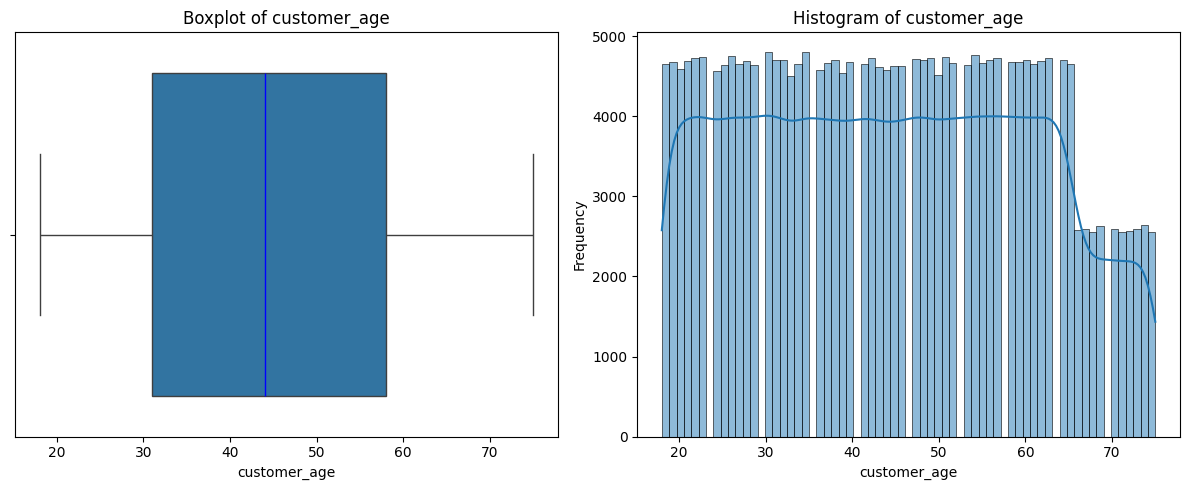

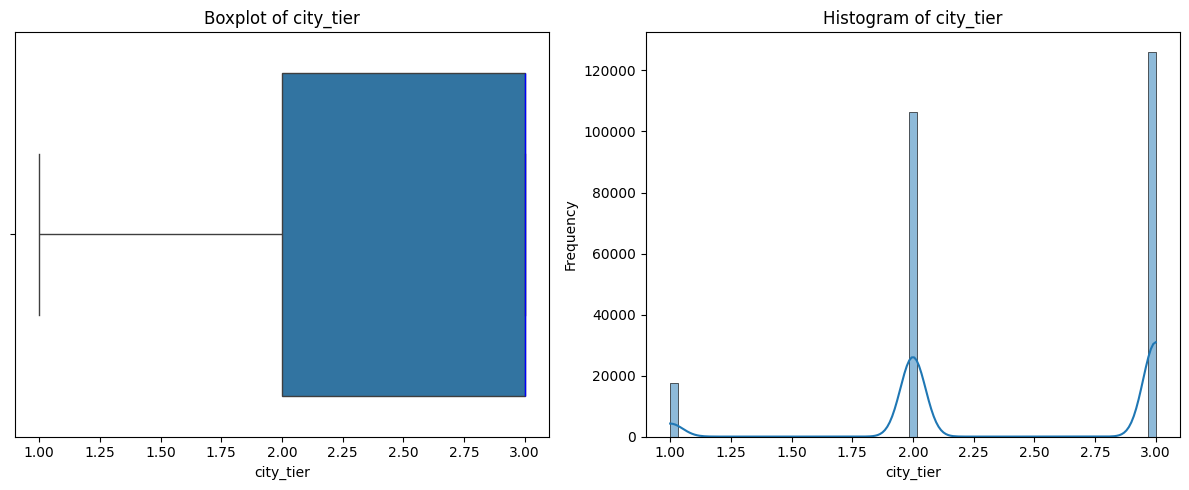

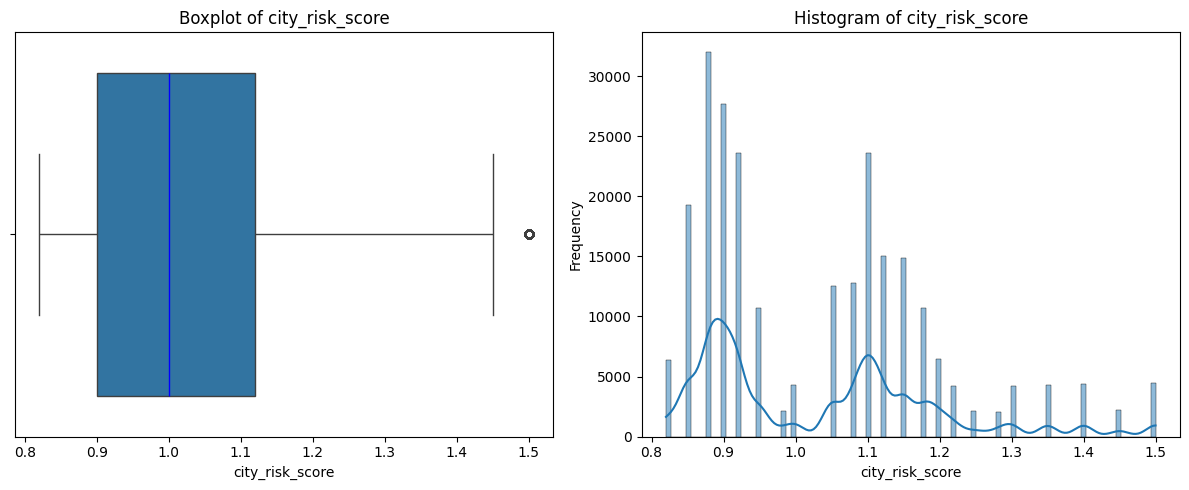

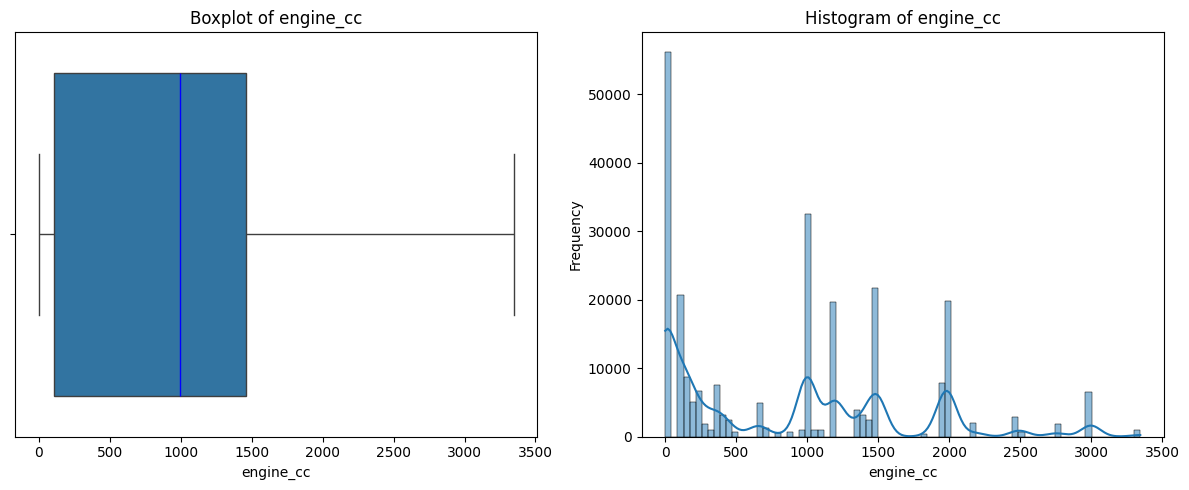

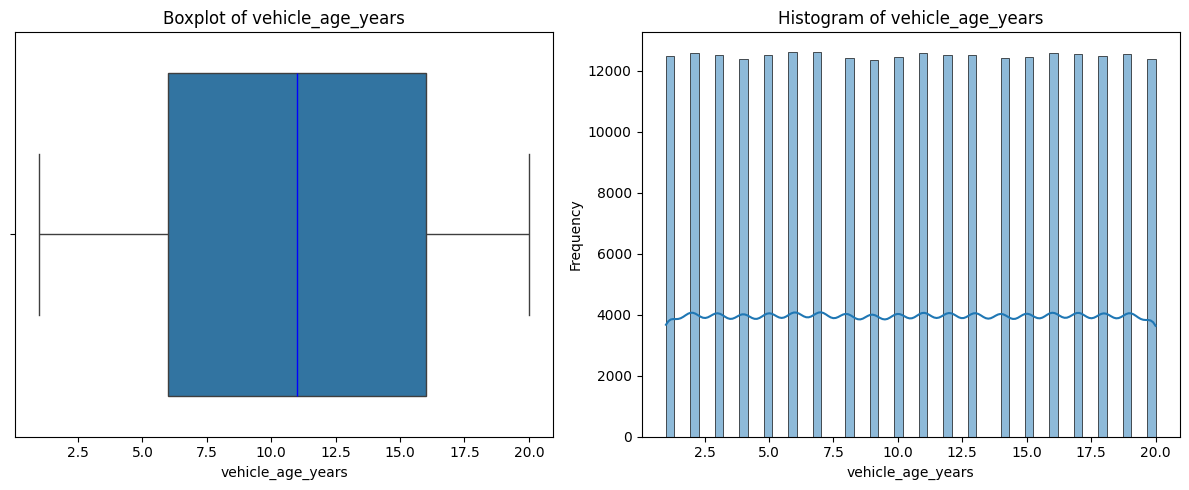

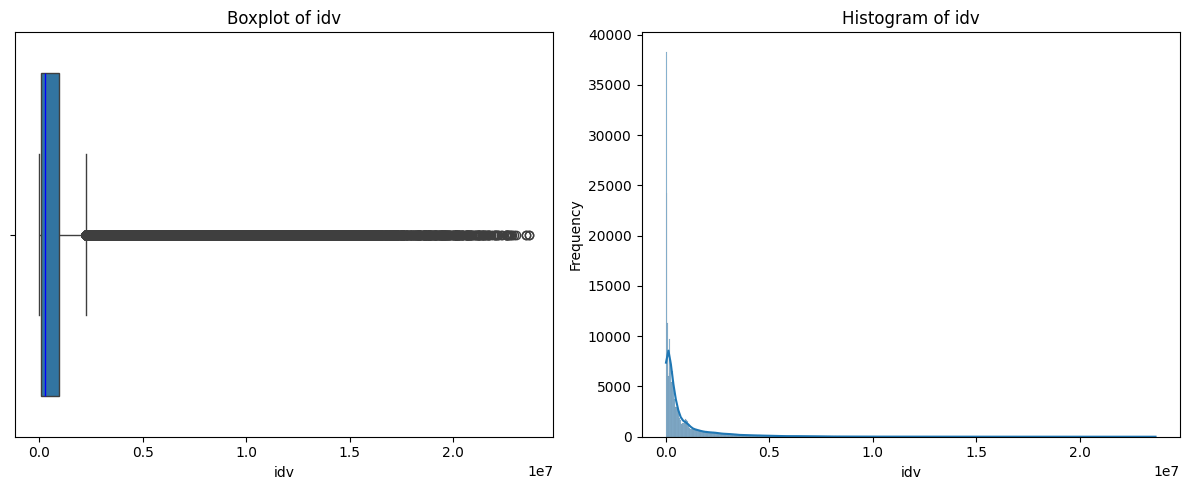

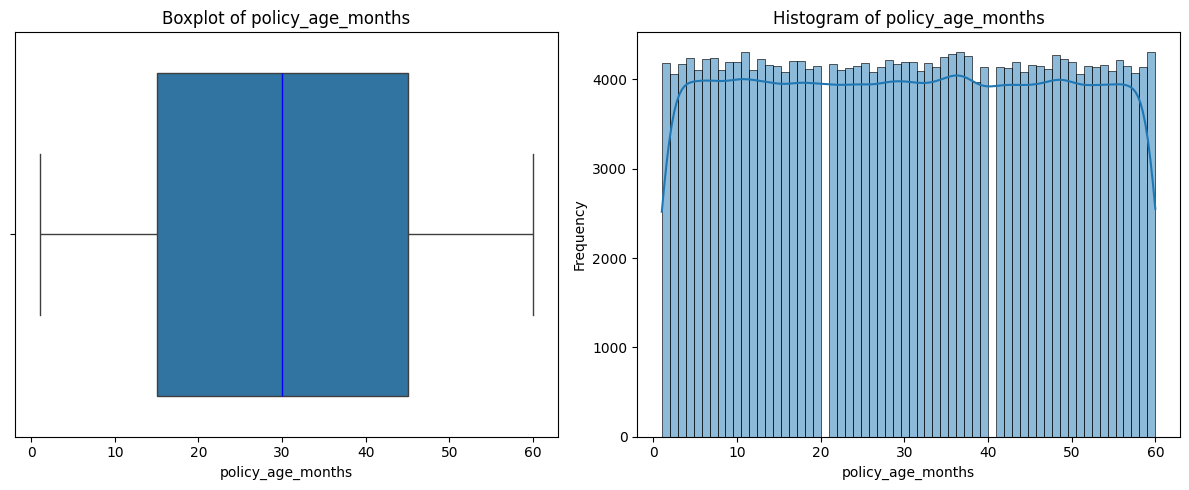

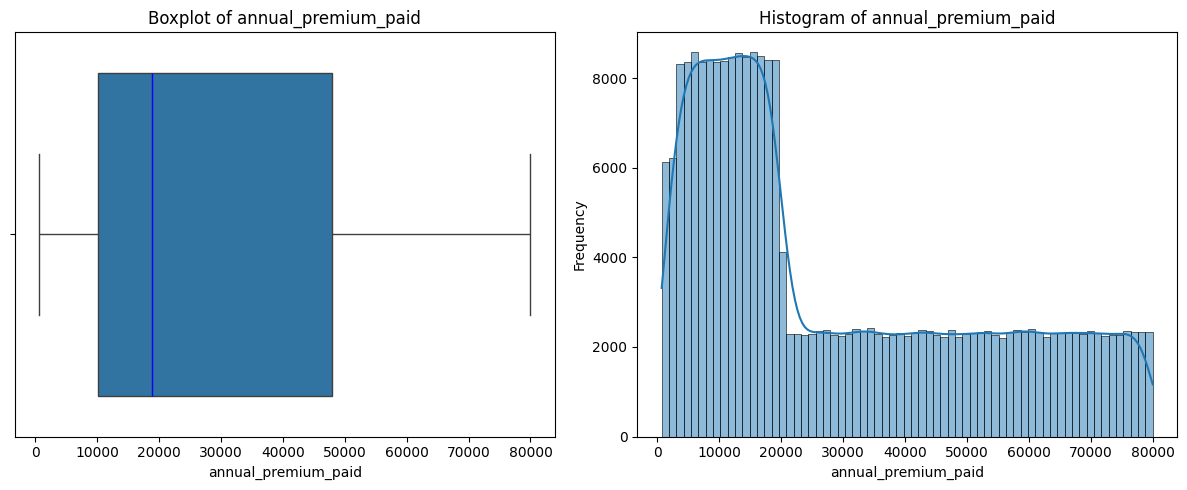

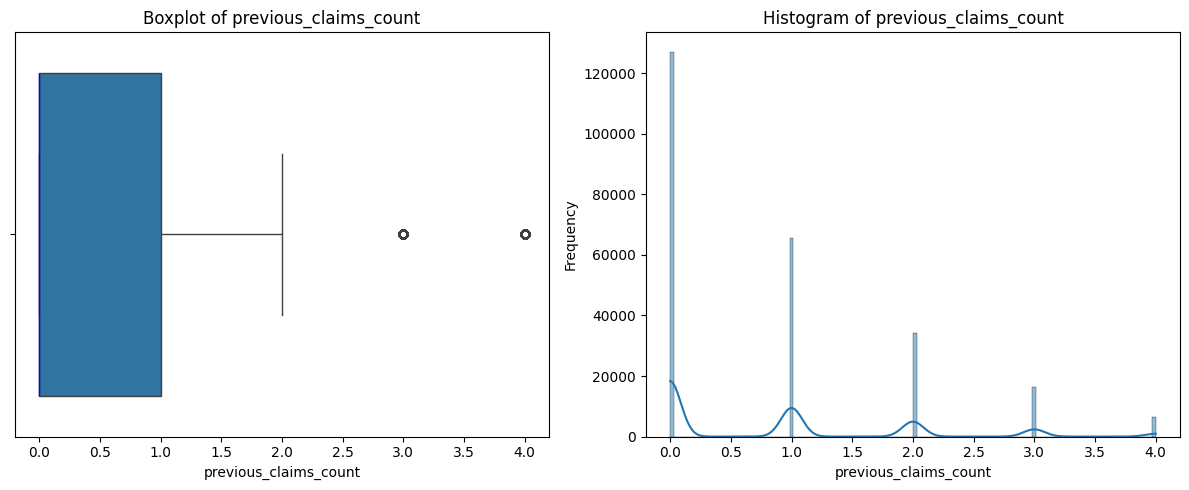

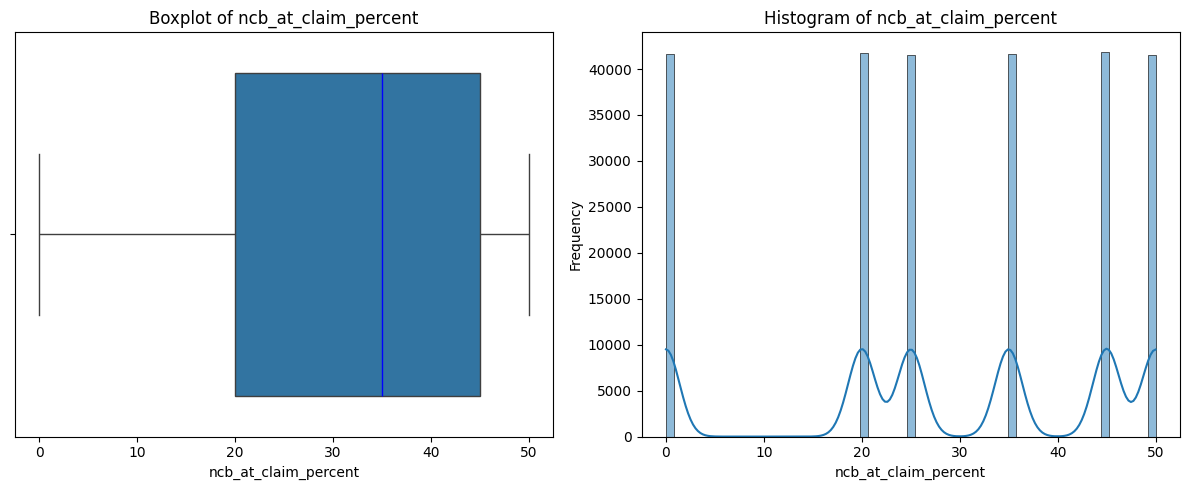

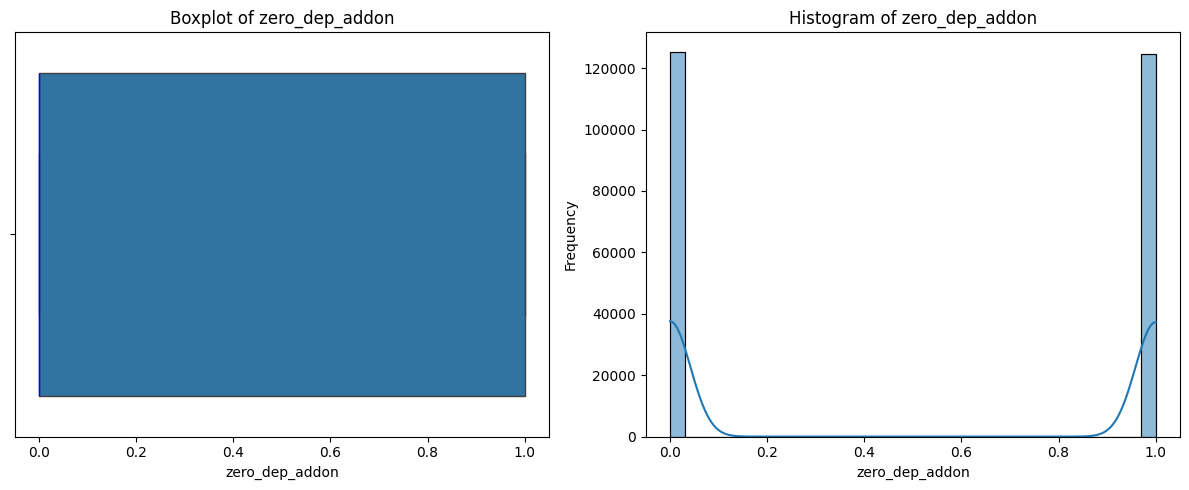

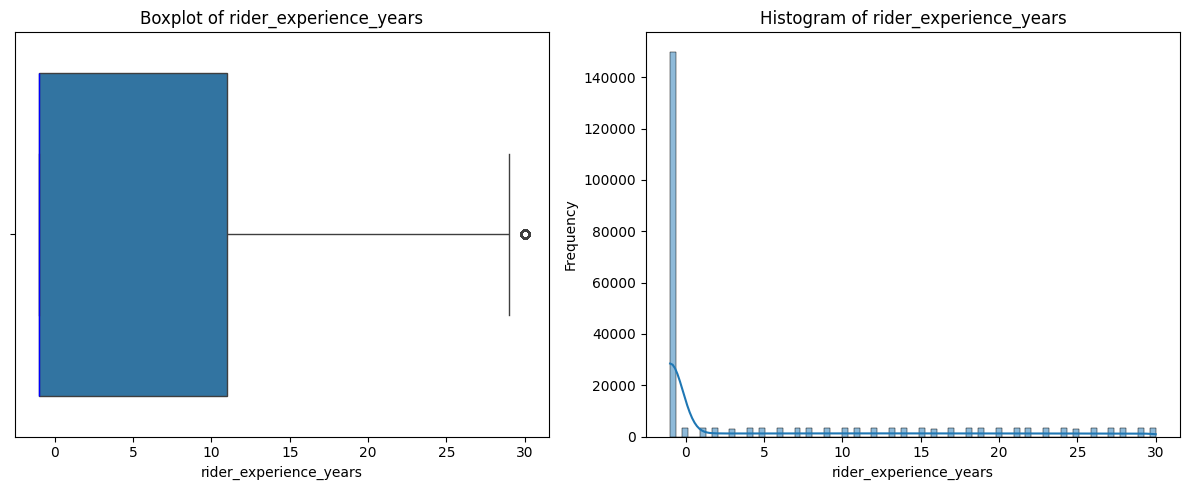

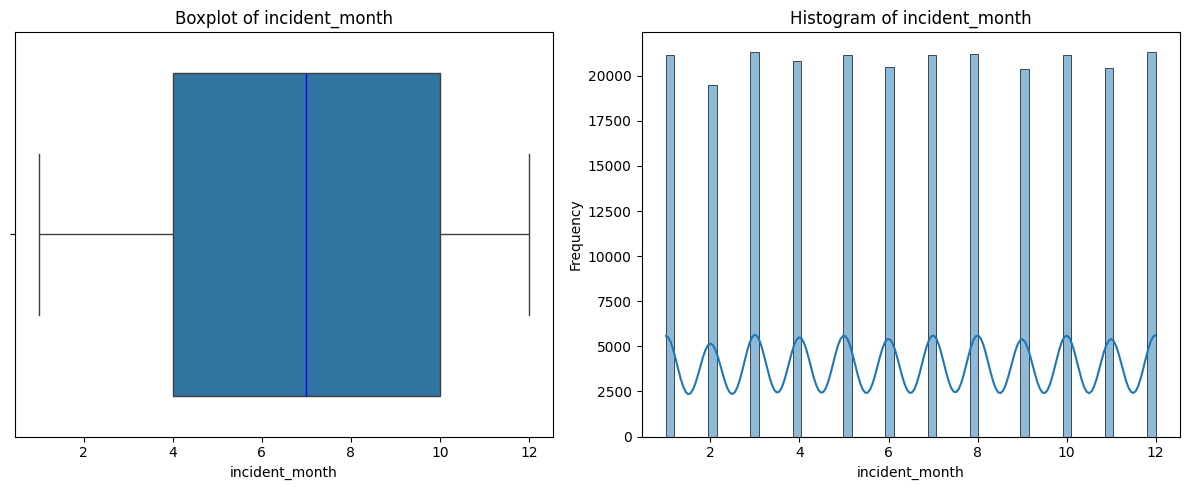

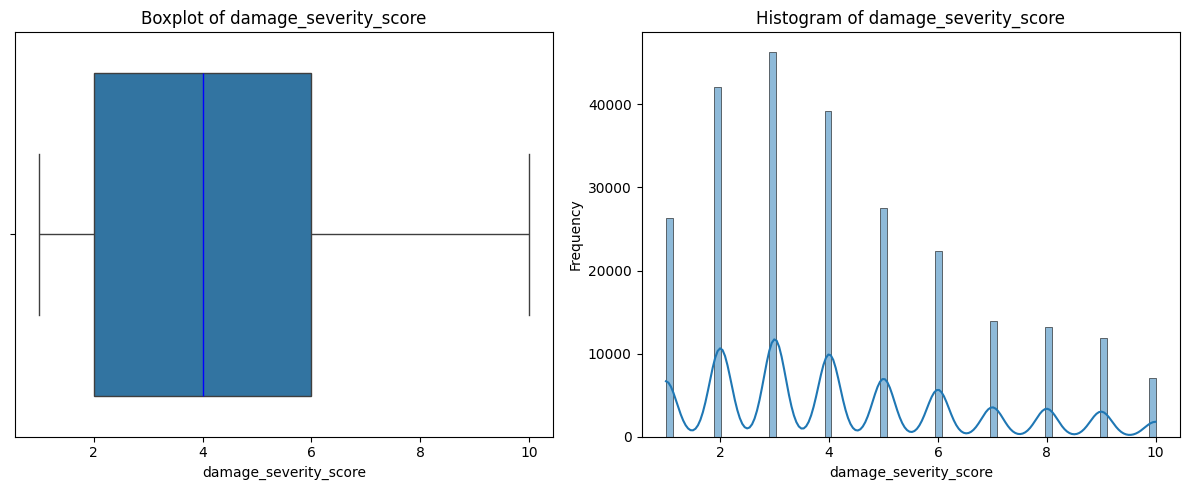

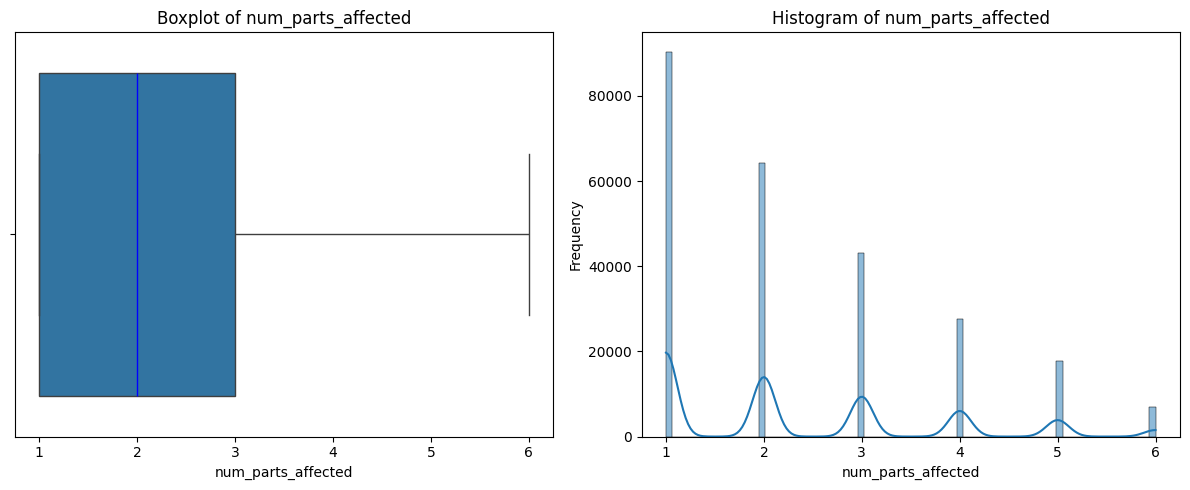

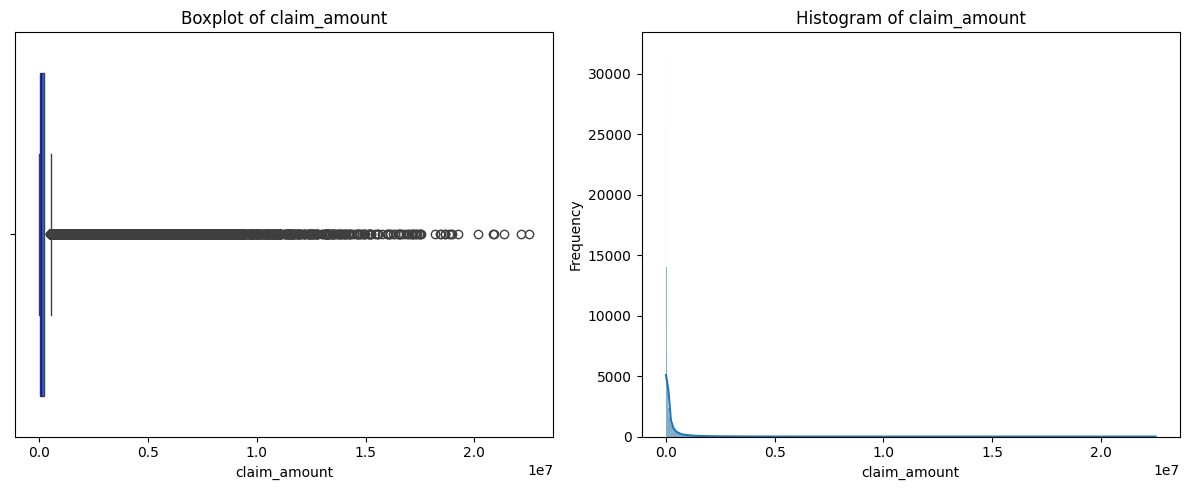

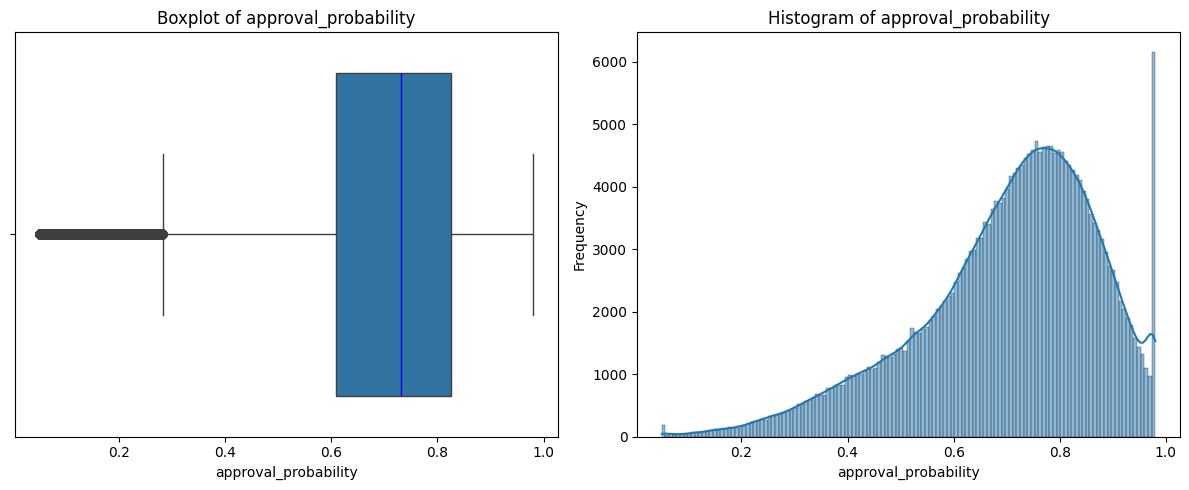

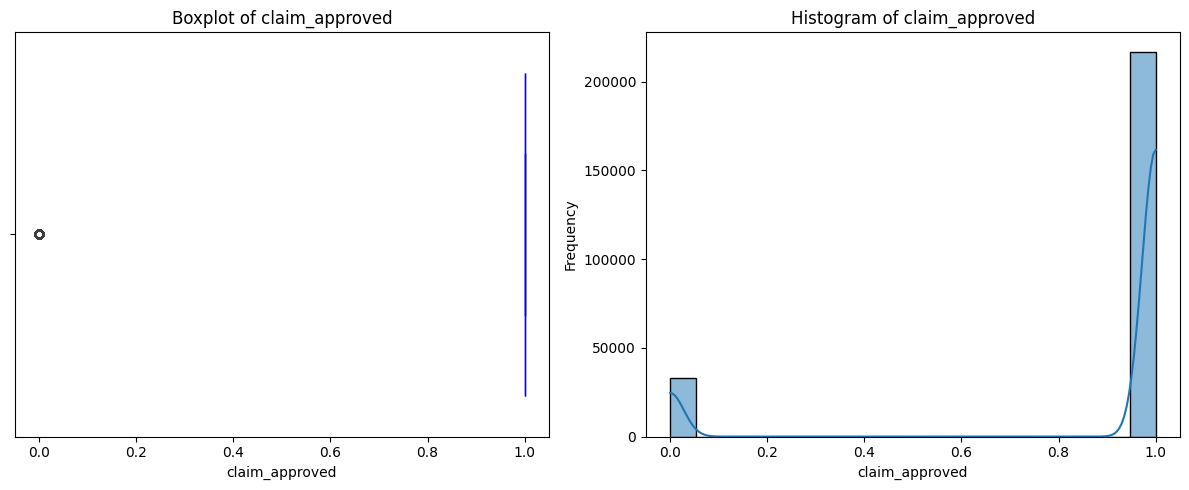

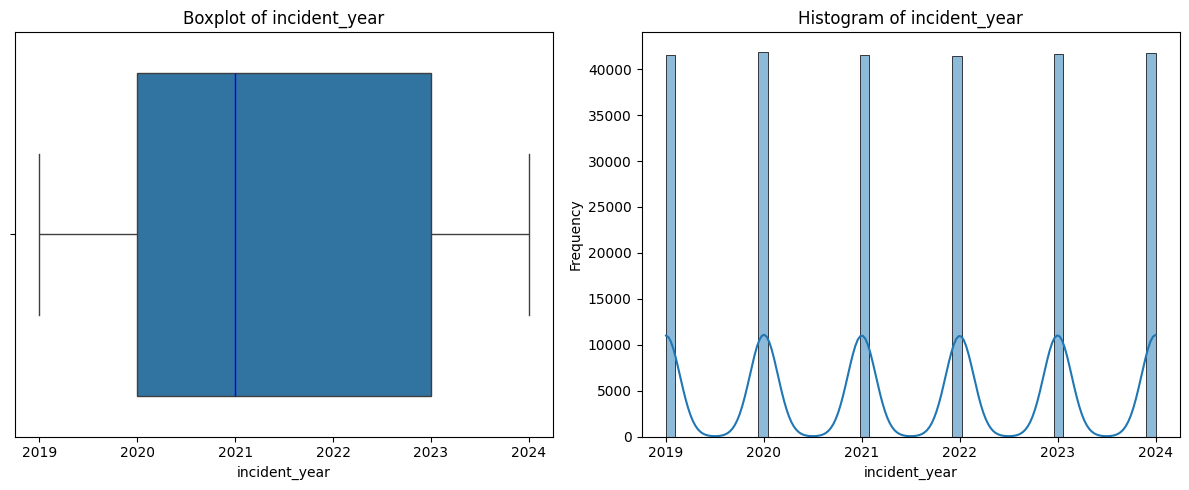

In [35]:
for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sns.boxplot(x=num_cols[col], medianprops={'color': 'blue'}, ax=axes[0])
    axes[0].set_title(f'Boxplot of {col}')
    axes[0].set_xlabel(col)

    sns.histplot(x=num_cols[col], kde=True, ax=axes[1])
    axes[1].set_title(f'Histogram of {col}')
    axes[1].set_xlabel(col)
    axes[1].set_ylabel('Frequency')

    plt.tight_layout()
    plt.show()

In [36]:
#cat_cols

In [37]:
for col in cat_cols_ohe:
    cat_cols_ohe[col] = cat_cols_ohe[col].apply(lambda x: x.lower().strip() if isinstance(x, str) else x
)

In [38]:
skip_cols = ['city', 'state', 'vehicle_model']

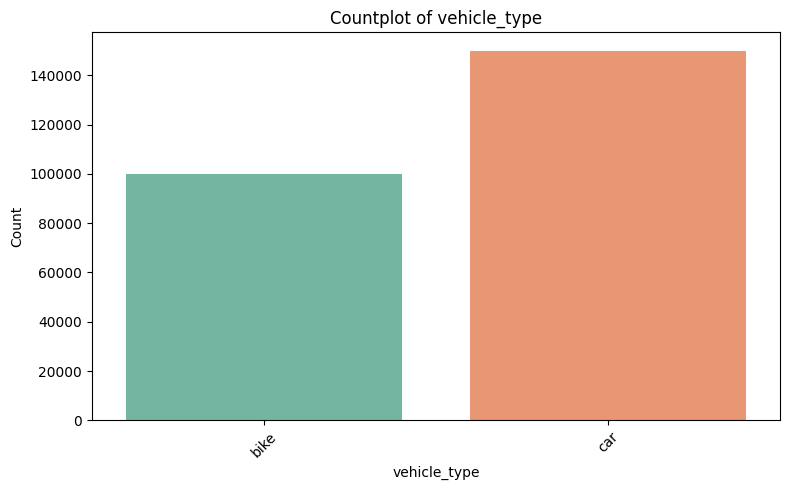

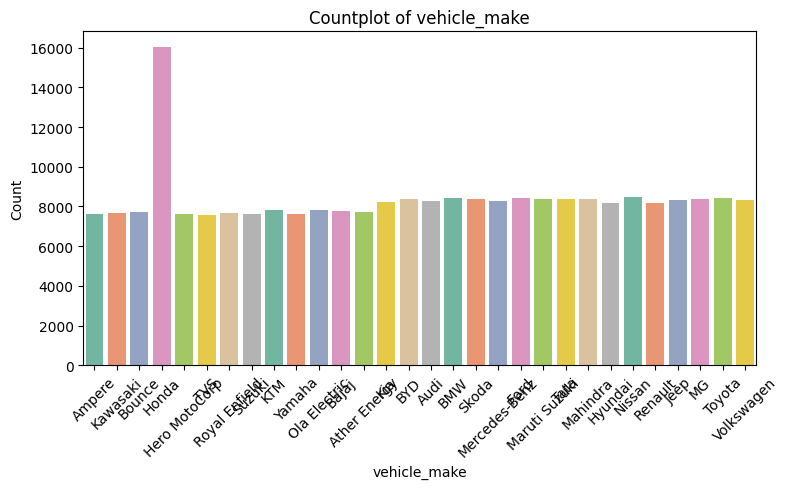

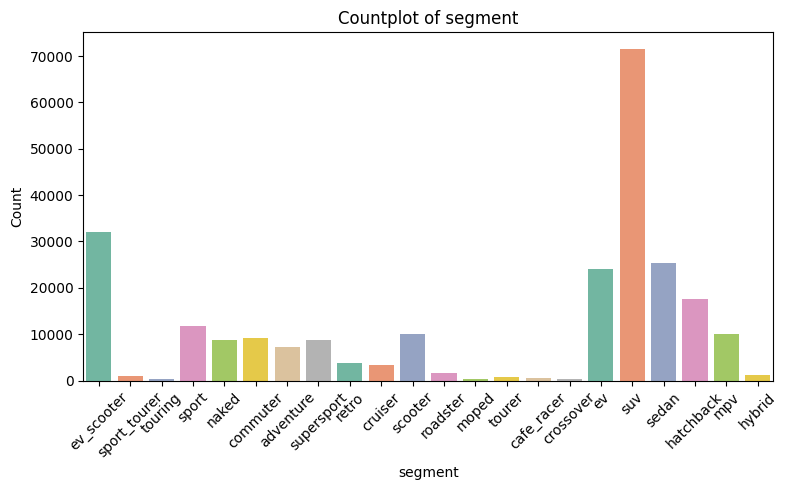

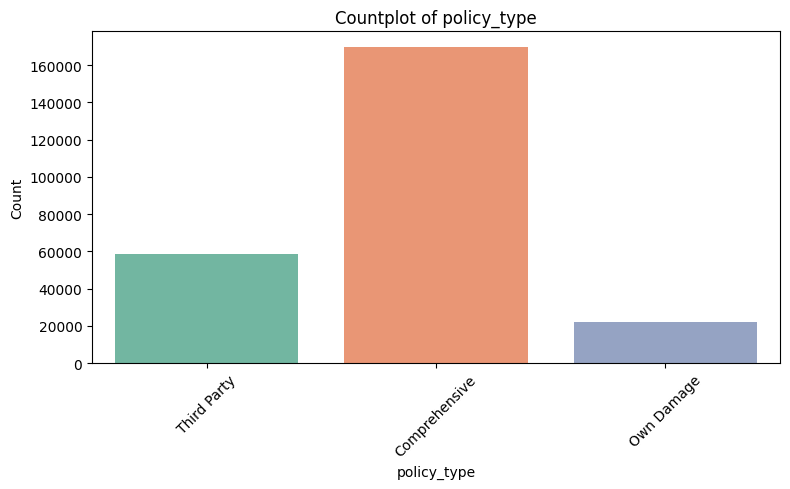

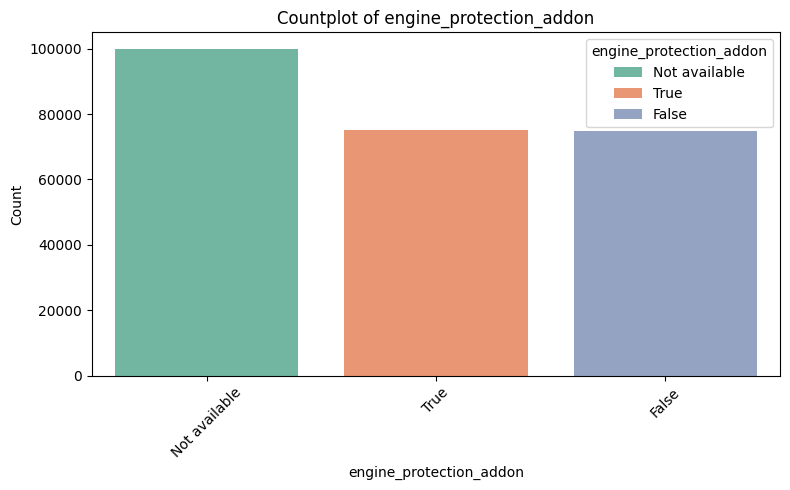

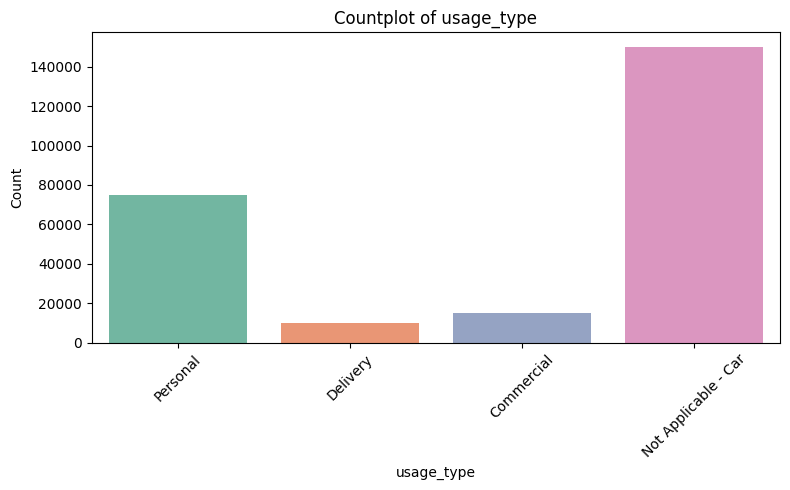

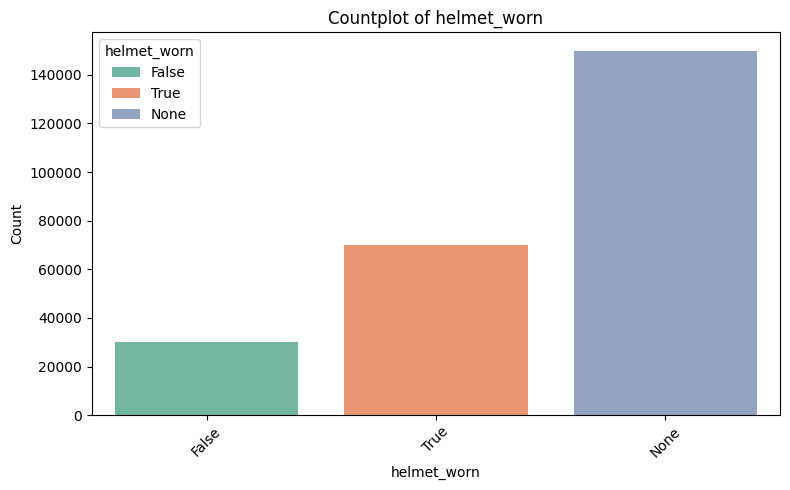

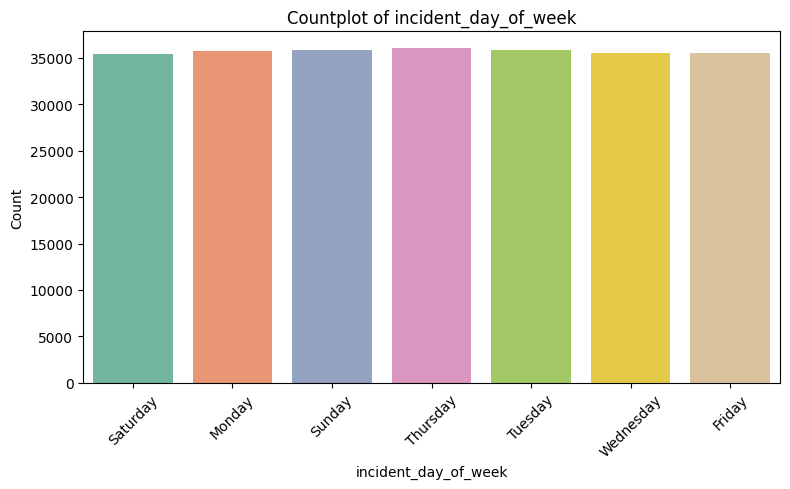

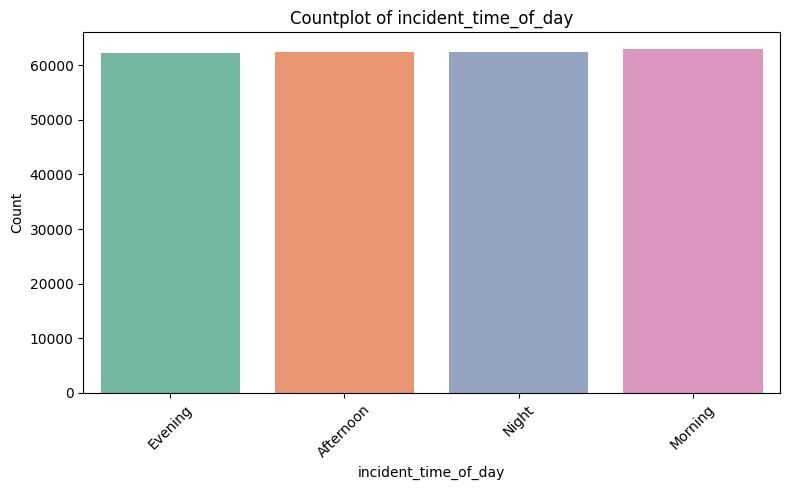

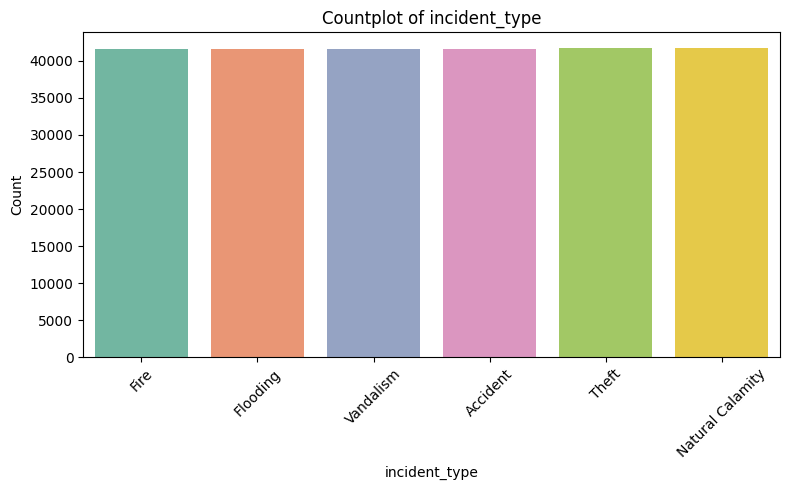

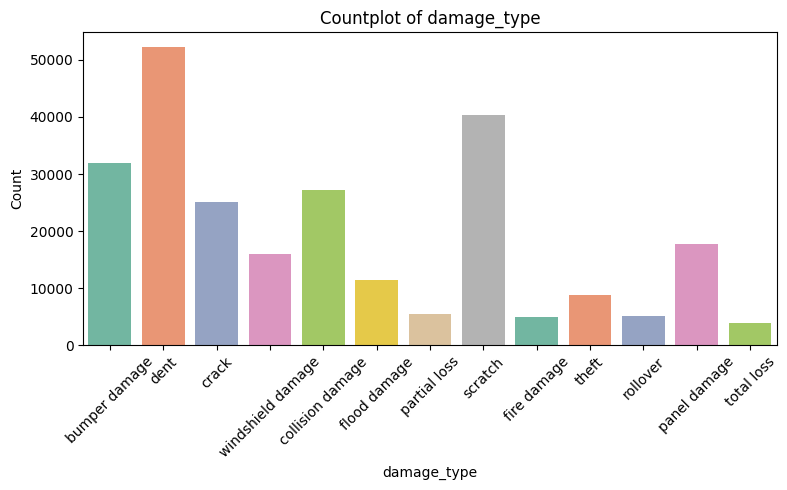

In [39]:
for col in cat_cols_ohe:
    if col in  skip_cols:
        continue
     

    plt.figure(figsize=(8, 5))

    ax = sns.countplot(x=claims_df[col], palette='Set2', hue=claims_df[col])

    ax.set_title(f'Countplot of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### Bivariate Analysis

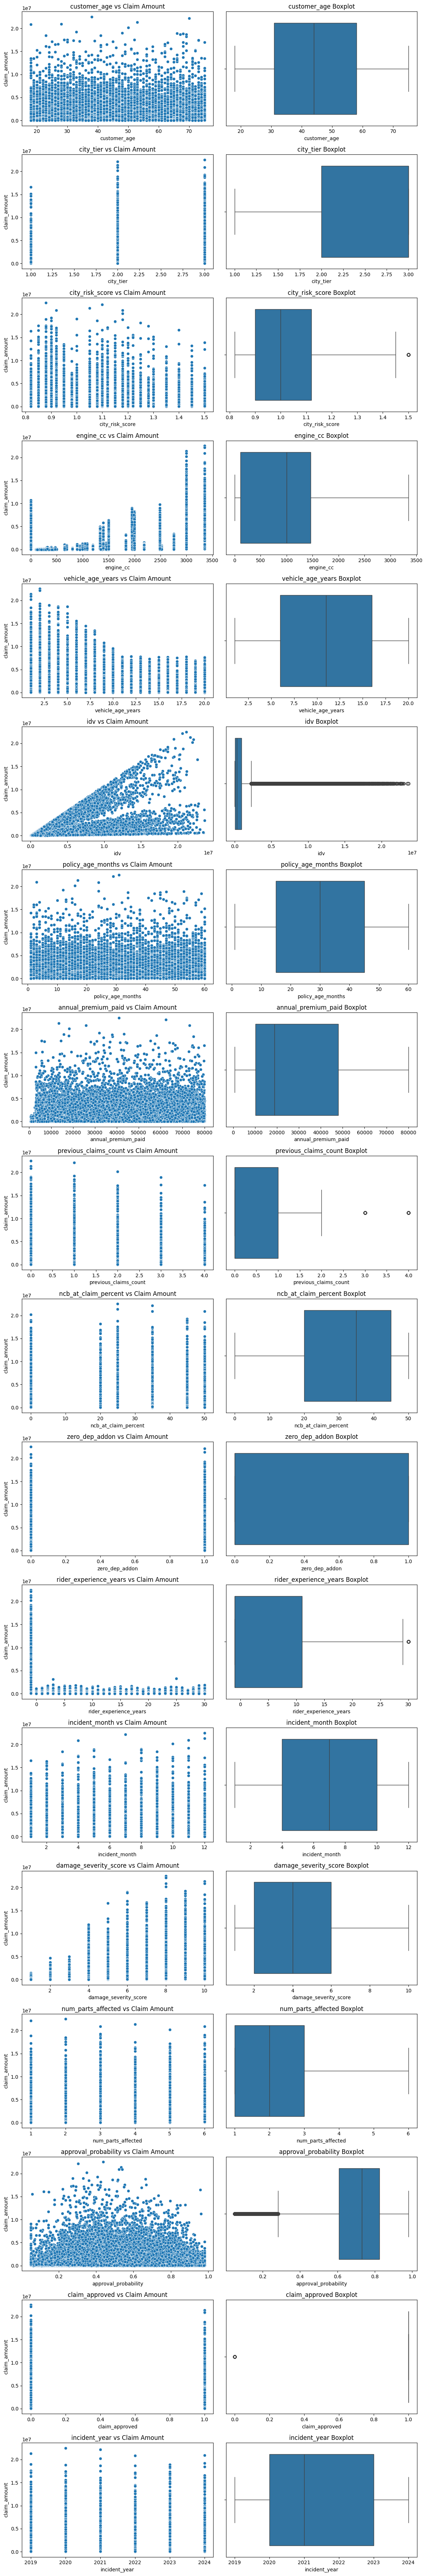

In [40]:
features = [col for col in num_cols if col != 'claim_amount']

fig, ax = plt.subplots(len(features), 2, figsize=(12, 4*len(features)))
for i, col in enumerate(features):

    # Scatterplot
    sns.scatterplot(
        x=claims_df[col],
        y=claims_df['claim_amount'],
        ax=ax[i,0]
    )

    ax[i,0].set_title(f"{col} vs {'Claim Amount'}")

    # Boxplot
    sns.boxplot(
        x=claims_df[col],
        ax=ax[i,1]
    )

    ax[i,1].set_title(f"{col} Boxplot")

plt.tight_layout()
plt.show()

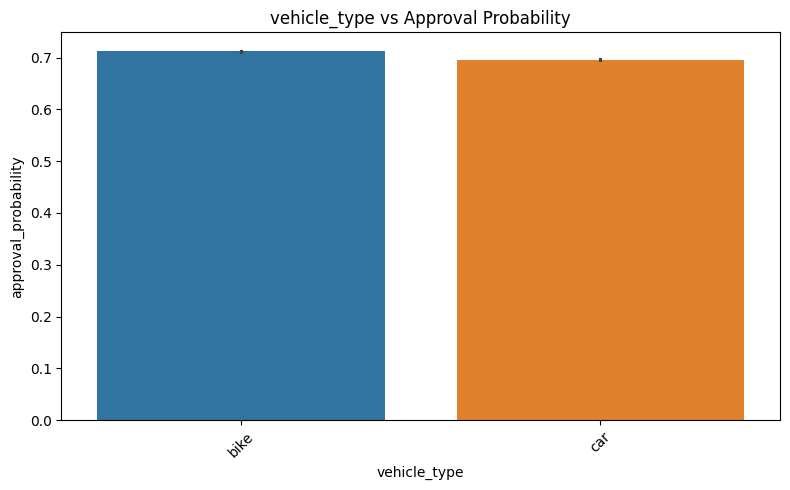

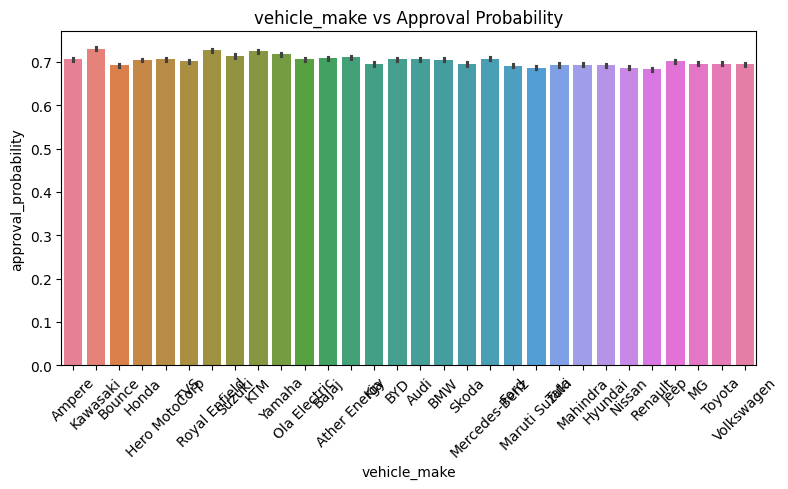

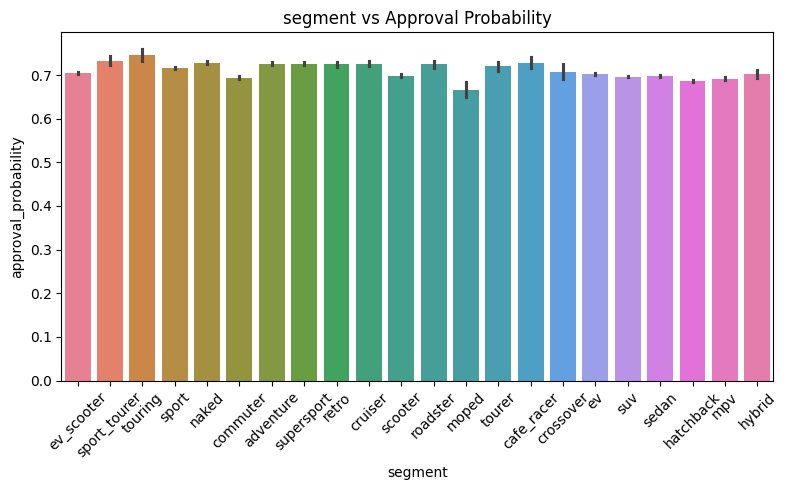

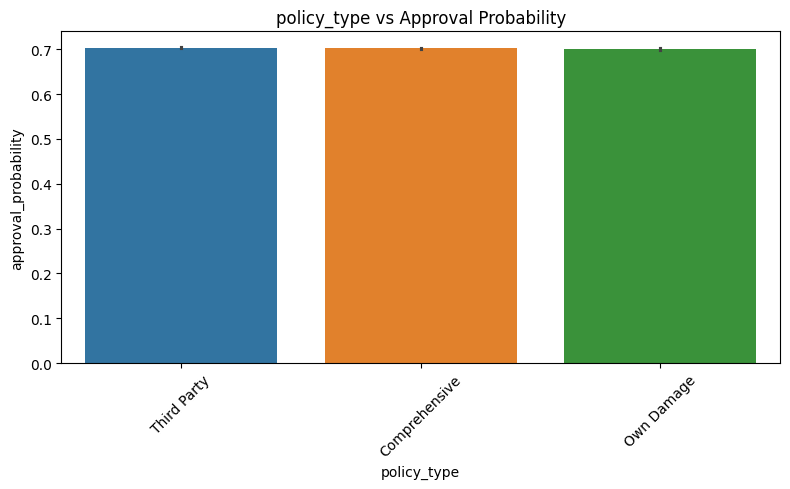

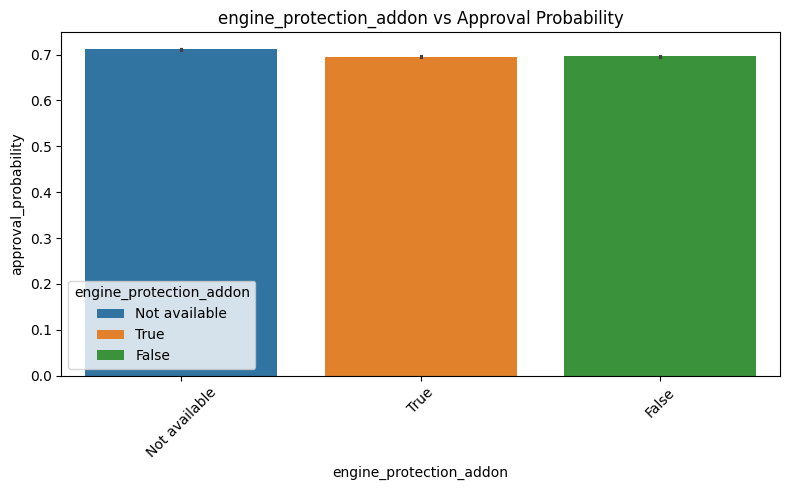

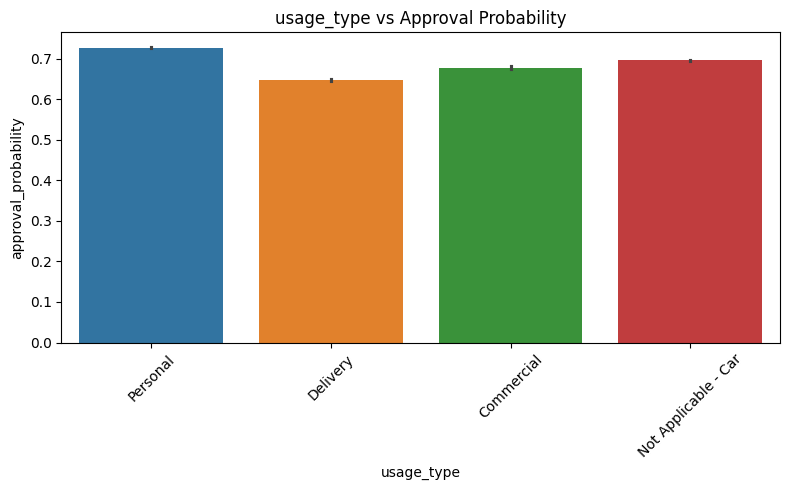

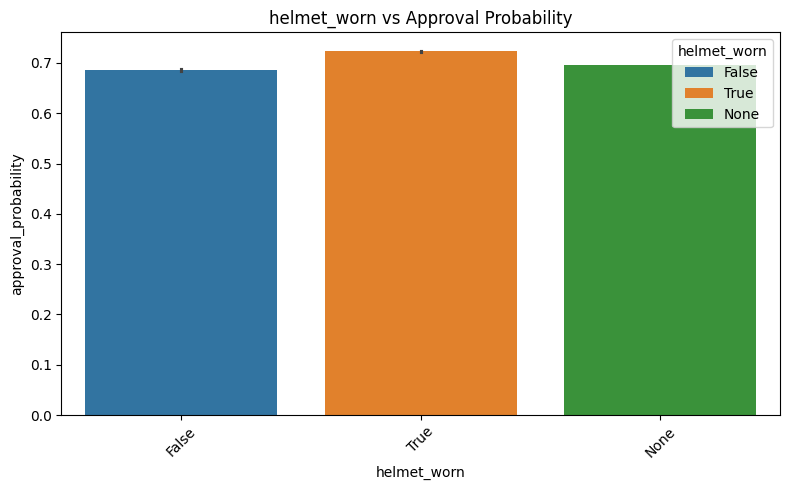

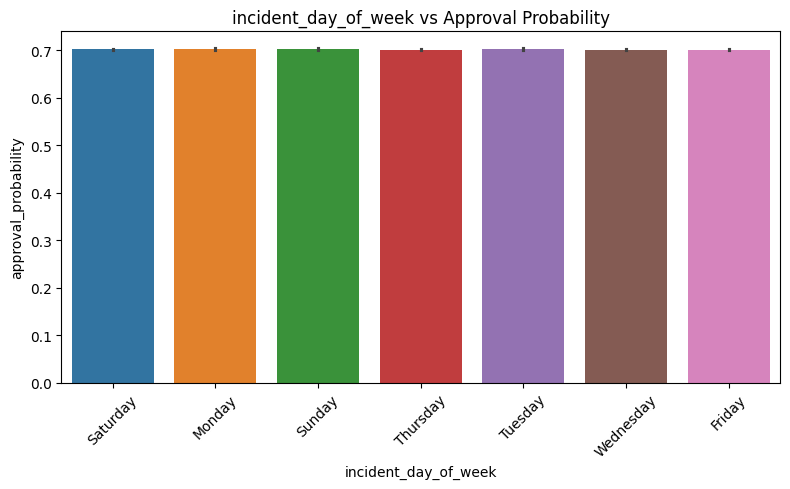

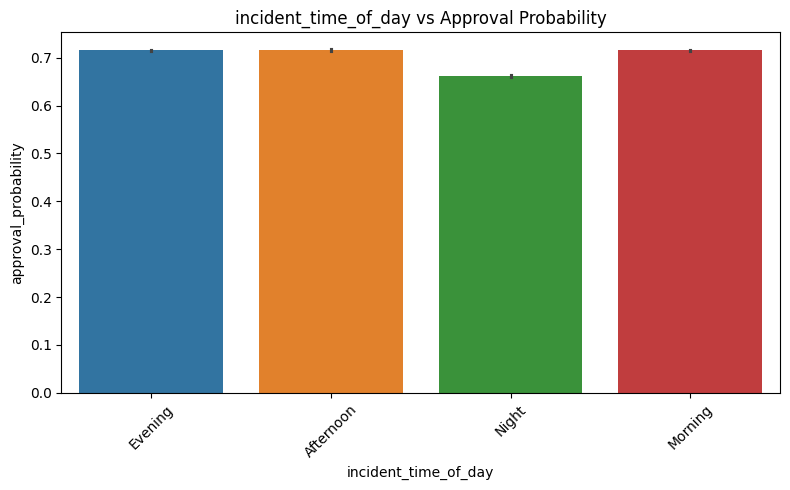

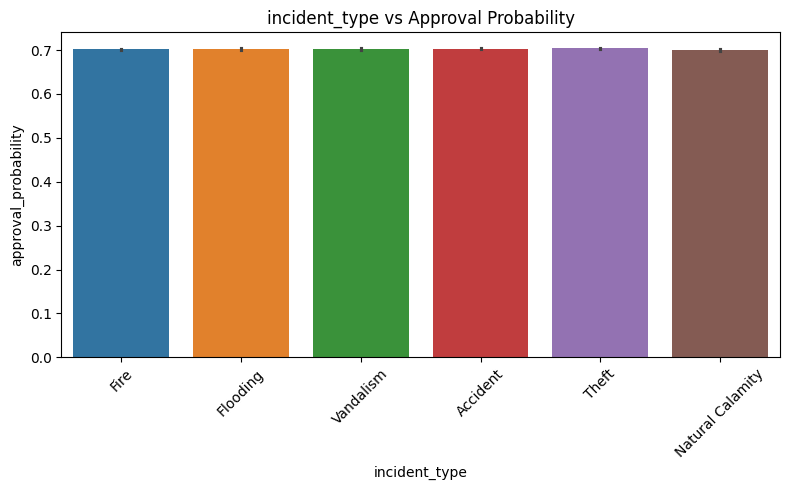

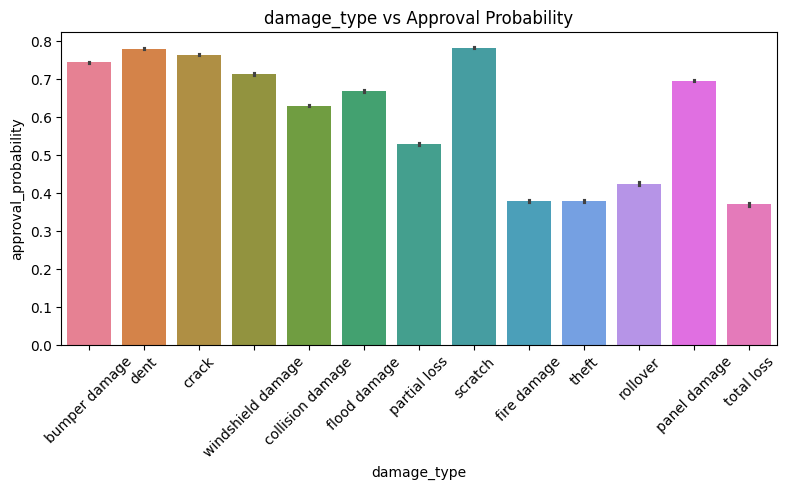

In [41]:
for col in cat_cols_ohe:
    if col in skip_cols:
        continue

    plt.figure(figsize=(8,5))

    sns.barplot(
        data=claims_df,
        x=col,
        y='approval_probability',
        hue= col
    )

    plt.xticks(rotation=45)
    plt.title(f'{col} vs Approval Probability')
    plt.tight_layout()
    plt.show()


### Multivariate Analysis

In [42]:
corr_matrix= num_cols.corr()
corr_matrix

,customer_age,city_tier,city_risk_score,engine_cc,vehicle_age_years,idv,policy_age_months,annual_premium_paid,previous_claims_count,ncb_at_claim_percent,zero_dep_addon,rider_experience_years,incident_month,damage_severity_score,num_parts_affected,claim_amount,approval_probability,claim_approved,incident_year
customer_age,1.000000,-0.001226,0.001602,0.103093,0.002157,0.059001,0.000045,0.102131,0.006741,-0.000239,-0.002354,-0.124964,-0.000696,0.004243,0.014038,0.039952,-0.006704,-0.005329,0.002163
city_tier,-0.001226,1.000000,-0.943249,-0.001429,-0.004726,-0.001163,-0.001639,0.000283,-0.001083,0.000383,-0.002062,-0.001246,-0.000884,0.003704,0.001060,0.002349,0.017644,0.006719,0.000878
city_risk_score,0.001602,-0.943249,1.000000,0.001131,0.004630,0.001108,0.001366,-0.000998,0.000630,0.000151,0.000490,0.000597,-0.000419,-0.003349,-0.001177,-0.002070,-0.018803,-0.007757,-0.000487
engine_cc,0.103093,-0.001429,0.001131,1.000000,0.000995,0.515719,0.001619,0.428642,0.032235,0.001468,0.003152,-0.528966,-0.000966,0.018394,0.045897,0.344426,-0.017477,-0.018893,-0.000493
vehicle_age_years,0.002157,-0.004726,0.004630,0.000995,1.000000,-0.219797,-0.001187,-0.000036,-0.000542,0.001800,0.001776,0.000621,-0.003117,-0.002588,-0.001894,-0.141683,-0.029765,-0.019622,-0.000614
idv,0.059001,-0.001163,0.001108,0.515719,-0.219797,1.000000,-0.000199,0.253489,0.018870,0.000516,0.000476,-0.308448,-0.000257,0.009400,0.027670,0.650696,0.004507,-0.000563,-0.001954
policy_age_months,0.000045,-0.001639,0.001366,0.001619,-0.001187,-0.000199,1.000000,0.001073,-0.001742,-0.003126,0.001810,0.001196,-0.000901,0.001237,0.002115,0.002235,0.133031,0.075057,-0.000791
annual_premium_paid,0.102131,0.000283,-0.000998,0.428642,-0.000036,0.253489,0.001073,1.000000,0.032175,-0.001057,0.002641,-0.531422,-0.001226,0.019816,0.047972,0.173410,-0.033609,-0.030424,-0.000613
previous_claims_count,0.006741,-0.001083,0.000630,0.032235,-0.000542,0.018870,-0.001742,0.032175,1.000000,0.000248,-0.000244,-0.040655,-0.000617,-0.000461,0.000985,0.010352,-0.405174,-0.205465,0.000119
ncb_at_claim_percent,-0.000239,0.000383,0.000151,0.001468,0.001800,0.000516,-0.003126,-0.001057,0.000248,1.000000,-0.002606,0.000968,-0.002206,0.000419,0.000892,0.001179,0.087230,0.037845,-0.003664


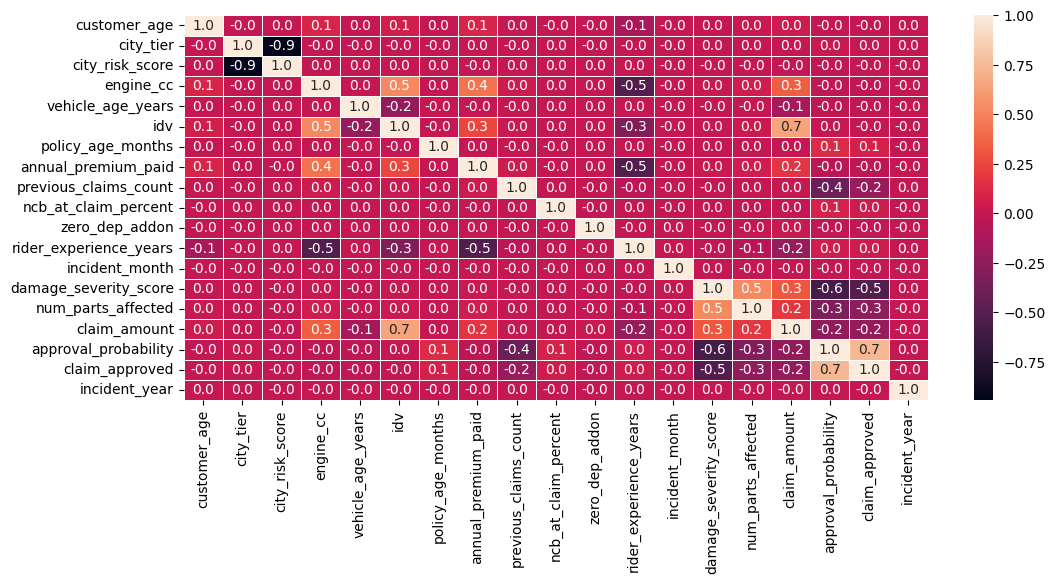

In [43]:
plt.figure(figsize=(12,5))
sns.heatmap(corr_matrix, annot=True, fmt='.1f', linewidths=0.5)
plt.show()

### Splitting X and Y

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, RobustScaler
import category_encoders as ce
from sklearn.compose import ColumnTransformer

In [45]:
bike_df= claims_df[claims_df['vehicle_type']== 'bike'].reset_index(drop=True)
car_df= claims_df[claims_df['vehicle_type']== 'car'].reset_index(drop=True)

In [46]:
#bike

In [47]:
x_bike= bike_df.drop(columns=["claim_amount", "approval_probability", "claim_approved"])
y_reg_bike= bike_df['claim_amount']
y_cls_bike= bike_df['claim_approved']

In [48]:
x_bike_train, x_test_bike, y_reg_bike_train, y_reg_bike_test, y_cls_bike_train, y_cls_bike_test= train_test_split(
    x_bike, y_reg_bike, y_cls_bike, test_size=0.2, random_state=42
)

In [49]:
x_bike_train.shape, x_test_bike.shape, y_reg_bike_train.shape, y_reg_bike_test.shape, y_cls_bike_train.shape, y_cls_bike_test.shape

((80000, 31), (20000, 31), (80000,), (20000,), (80000,), (20000,))

In [50]:
#car_df

In [51]:
x_car = car_df.drop(columns=["claim_amount", "approval_probability", "claim_approved"])
y_reg_car = car_df['claim_amount']
y_cls_car = car_df['claim_approved']

In [52]:
x_car_train, x_car_test, y_reg_car_train, y_reg_car_test, y_cls_car_train, y_cls_car_test = train_test_split(
    x_car, y_reg_car, y_cls_car, test_size=0.2, random_state=42
)

In [53]:
x_car_train.shape, x_car_test.shape, y_reg_car_train.shape, y_reg_car_test.shape, y_cls_car_train.shape, y_cls_car_test.shape

((120000, 31), (30000, 31), (120000,), (30000,), (120000,), (30000,))

In [54]:
claims_df.dtypes

customer_age                 int64
city                        object
state                       object
city_tier                    int64
city_risk_score            float64
vehicle_type                object
vehicle_make                object
vehicle_model               object
segment                     object
engine_cc                    int64
vehicle_age_years            int64
idv                        float64
policy_type                 object
policy_age_months            int64
annual_premium_paid        float64
previous_claims_count        int64
ncb_at_claim_percent         int64
zero_dep_addon                bool
engine_protection_addon     object
usage_type                  object
rider_experience_years       int64
helmet_worn                 object
incident_day_of_week        object
incident_month               int64
incident_time_of_day        object
incident_type               object
damage_type                 object
damage_severity_score        int64
num_parts_affected  

In [55]:
cat_cols_ohe.select_dtypes(include='object').nunique()

city                       117
state                       32
vehicle_type                 2
vehicle_make                30
vehicle_model              272
segment                     22
policy_type                  3
engine_protection_addon      3
usage_type                   4
helmet_worn                  3
incident_day_of_week         7
incident_time_of_day         4
incident_type                6
damage_type                 13
dtype: int64

### Encoding and Scaling

In [56]:
#bike_df_columns

In [57]:
bike_x_train_ohe = ["policy_type", "usage_type", "incident_day_of_week",
                     "incident_time_of_day", "incident_type", "damage_type",
                     "city_tier", "helmet_worn"]

bike_x_train_num = ['customer_age', 'city_risk_score', 'engine_cc', 'vehicle_age_years',
                     'idv', 'policy_age_months', 'annual_premium_paid',
                     'previous_claims_count', 'ncb_at_claim_percent', 'zero_dep_addon',
                     'rider_experience_years', 'incident_month', 'damage_severity_score',
                     'num_parts_affected', 'incident_year']

In [58]:
#car_df_columns

In [59]:
car_x_train_ohe = ["policy_type", "incident_day_of_week", "incident_time_of_day",
                    "incident_type", "damage_type", "city_tier", "engine_protection_addon"]

car_x_train_num = ['customer_age', 'city_risk_score', 'engine_cc', 'vehicle_age_years',
                    'idv', 'policy_age_months', 'annual_premium_paid',
                    'previous_claims_count', 'ncb_at_claim_percent', 'zero_dep_addon',
                    'incident_month', 'damage_severity_score', 'num_parts_affected',
                    'incident_year']

In [60]:
#common columns for both df

In [61]:
x_train_target = ["city", "state", "vehicle_make", "vehicle_model", "segment"]
x_train_mlb = ["affected_parts"]

In [62]:
# bike- encoding and scaling

In [63]:
# Onehotencoding and Robust scaling

In [64]:
bike_preprocessor= ColumnTransformer(
    transformers= (
       ( 'num', RobustScaler(), bike_x_train_num),
       ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore'), bike_x_train_ohe) 
    )
)

In [65]:
bike_preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","(('num', ...), ...)"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``

In [66]:
x_bike_train_preprocessed= bike_preprocessor.fit_transform(x_bike_train)
x_bike_test_preprocessed= bike_preprocessor.transform(x_test_bike)

In [67]:
#Muiltilabelbinazer

In [68]:
mlb_bike= MultiLabelBinarizer()

affected_parts_train= mlb_bike.fit_transform(x_bike_train['affected_parts'])
affected_parts_test= mlb_bike.transform(x_test_bike['affected_parts'])


In [69]:
#target encoding for claim_amount

In [70]:
target_encoder_bike_amount = ce.TargetEncoder(cols=x_train_target)
target_encoder_bike_amount.fit(x_bike_train[x_train_target], y_reg_bike_train)
target_encoded_train_amount = target_encoder_bike_amount.transform(x_bike_train[x_train_target])
target_encoded_test_amount = target_encoder_bike_amount.transform(x_test_bike[x_train_target])

In [71]:
#target encoding for approval

In [72]:
target_encoder_bike_approved = ce.TargetEncoder(cols=x_train_target)
target_encoder_bike_approved.fit(x_bike_train[x_train_target], y_cls_bike_train)
target_encoded_train_approved = target_encoder_bike_approved.transform(x_bike_train[x_train_target])
target_encoded_test_approved = target_encoder_bike_approved.transform(x_test_bike[x_train_target])

In [73]:
feature_names_bike= bike_preprocessor.get_feature_names_out()

In [74]:
x_bike_train_preprocessed_df = pd.DataFrame(x_bike_train_preprocessed, columns=feature_names_bike).reset_index(drop=True)
x_bike_test_preprocessed_df = pd.DataFrame(x_bike_test_preprocessed, columns=feature_names_bike).reset_index(drop=True)

affected_parts_train_df = pd.DataFrame(affected_parts_train, columns=mlb_bike.classes_).reset_index(drop=True)
affected_parts_test_df = pd.DataFrame(affected_parts_test, columns=mlb_bike.classes_).reset_index(drop=True)

target_encoded_train_amount = target_encoded_train_amount.reset_index(drop=True)
target_encoded_test_amount = target_encoded_test_amount.reset_index(drop=True)


target_encoded_train_approved = target_encoded_train_approved.reset_index(drop=True)
target_encoded_test_approved = target_encoded_test_approved.reset_index(drop=True)

In [75]:
#final concat

In [76]:
X_bike_train_final_amount = pd.concat(
    [x_bike_train_preprocessed_df, affected_parts_train_df, target_encoded_train_amount], axis=1
)
X_bike_test_final_amount = pd.concat(
    [x_bike_test_preprocessed_df, affected_parts_test_df, target_encoded_test_amount], axis=1
)

X_bike_train_final_approved = pd.concat(
    [x_bike_train_preprocessed_df, affected_parts_train_df, target_encoded_train_approved], axis=1
)
X_bike_test_final_approved = pd.concat(
    [x_bike_test_preprocessed_df, affected_parts_test_df, target_encoded_test_approved], axis=1
)

In [77]:
# car- encoding and scaling

In [78]:
# Onehotencoding and Robust scaling

In [79]:
car_preprocessor= ColumnTransformer(
    transformers=(
        ('num', RobustScaler(), car_x_train_num),
        ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore'), car_x_train_ohe)
    )
)

In [80]:
car_preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","(('num', ...), ...)"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``

In [81]:
x_car_train_preprocessed= car_preprocessor.fit_transform(x_car_train)
x_car_test_preprocessed= car_preprocessor.transform(x_car_test)

In [82]:
#Muiltilabelbinazer

In [83]:
mlb_car= MultiLabelBinarizer()

affected_parts_car_train= mlb_car.fit_transform(x_car_train['affected_parts'])
affected_parts_car_test= mlb_car.transform(x_car_test['affected_parts'])

In [84]:
#target encoding for claim_amount

In [85]:
target_encoder_car_amount = ce.TargetEncoder(cols=x_train_target)
target_encoder_car_amount.fit(x_car_train[x_train_target], y_reg_car_train)
target_encoded_train_car_amount = target_encoder_car_amount.transform(x_car_train[x_train_target])
target_encoded_test_car_amount = target_encoder_car_amount.transform(x_car_test[x_train_target])

In [86]:
#target encoding for approval

In [87]:
target_encoder_car_approved = ce.TargetEncoder(cols=x_train_target)
target_encoder_car_approved.fit(x_car_train[x_train_target], y_cls_car_train)
target_encoded_train_car_approved = target_encoder_car_approved.transform(x_car_train[x_train_target])
target_encoded_test_car_approved = target_encoder_car_approved.transform(x_car_test[x_train_target])

In [88]:
feature_names_car=  car_preprocessor.get_feature_names_out()

In [89]:
x_car_train_preprocessed_df = pd.DataFrame(x_car_train_preprocessed, columns=feature_names_car).reset_index(drop=True)
x_car_test_preprocessed_df = pd.DataFrame(x_car_test_preprocessed, columns=feature_names_car).reset_index(drop=True)

affected_parts_train_car_df = pd.DataFrame(affected_parts_car_train, columns=mlb_car.classes_).reset_index(drop=True)
affected_parts_test_car_df = pd.DataFrame(affected_parts_car_test, columns=mlb_car.classes_).reset_index(drop=True)

target_encoded_car_train_amount = target_encoded_train_car_amount.reset_index(drop=True)
target_encoded_car_test_amount = target_encoded_test_car_amount.reset_index(drop=True)


target_encoded_car_train_approved = target_encoded_train_car_approved.reset_index(drop=True)
target_encoded_car_test_approved = target_encoded_test_car_approved.reset_index(drop=True)

In [90]:
#Final concat

In [91]:
X_car_train_final_amount = pd.concat(
    [x_car_train_preprocessed_df, affected_parts_train_car_df, target_encoded_car_train_amount], axis=1
)
X_car_test_final_amount = pd.concat(
    [x_car_test_preprocessed_df, affected_parts_test_car_df, target_encoded_car_test_amount], axis=1
)

X_car_train_final_approved = pd.concat(
    [x_car_train_preprocessed_df, affected_parts_train_car_df, target_encoded_car_train_approved], axis=1
)
X_car_test_final_approved = pd.concat(
    [x_car_test_preprocessed_df, affected_parts_test_car_df, target_encoded_car_test_approved], axis=1
)

###  Feature Selection

In [110]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import accuracy_score, r2_score, mean_absolute_error, f1_score
from sklearn.metrics import confusion_matrix, classification_report

In [93]:
#Regression 
#bike

In [94]:
rf_bike_amount= RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf_bike_amount.fit(X_bike_train_final_amount, y_reg_bike_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [95]:
importance_bike_amount= pd.DataFrame({
    'feature': X_bike_train_final_amount.columns,
    'importance': rf_bike_amount.feature_importances_
}).sort_values('importance', ascending=False)

In [96]:
importance_bike_amount

,feature,importance
4,num__idv,0.476597
12,num__damage_severity_score,0.346866
33,ohe__damage_type_collision damage,0.065554
37,ohe__damage_type_flood damage,0.019159
42,ohe__damage_type_theft,0.014828
...,...,...
22,ohe__incident_day_of_week_Thursday,0.000053
51,exhaust,0.000050
48,chain and sprocket,0.000043
59,headlight,0.000043


In [97]:
#Classification
#bike

In [118]:
rf_bike_approved= RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1, class_weight='balanced')
rf_bike_approved.fit(X_bike_train_final_approved, y_cls_bike_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

In [119]:
importance_bike_approved= pd.DataFrame({
    'feature': X_bike_train_final_approved.columns,
    'importance': rf_bike_approved.feature_importances_
}).sort_values('importance', ascending=False)

In [120]:
importance_bike_approved

,feature,importance
12,num__damage_severity_score,0.251256
42,ohe__damage_type_theft,0.104739
5,num__policy_age_months,0.072486
7,num__previous_claims_count,0.069057
36,ohe__damage_type_fire damage,0.052172
...,...,...
55,front mudguard,0.001364
21,ohe__incident_day_of_week_Sunday,0.001364
20,ohe__incident_day_of_week_Saturday,0.001357
51,exhaust,0.001338


In [101]:
#Regression
#car

In [102]:
rf_car_amount= RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf_car_amount.fit(X_car_train_final_amount, y_reg_car_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [103]:
importance_car_amount = pd.DataFrame({
    'feature': X_car_train_final_amount.columns,
    'importance': rf_car_amount.feature_importances_
}).sort_values('importance', ascending=False)
importance_car_amount

,feature,importance
4,num__idv,0.510258
11,num__damage_severity_score,0.340326
30,ohe__damage_type_collision damage,0.044666
34,ohe__damage_type_flood damage,0.027420
35,ohe__damage_type_panel damage,0.026226
...,...,...
58,radiator,0.000023
56,left headlight,0.000022
68,underbody,0.000019
16,ohe__incident_day_of_week_Monday,0.000019


In [104]:
#Classification
#Car

In [121]:
rf_car_approved= RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1, class_weight='balanced')
rf_car_approved.fit(X_car_train_final_approved, y_cls_car_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_feat

In [122]:
importance_car_approved = pd.DataFrame({
    'feature': X_car_train_final_approved.columns,
    'importance': rf_car_approved.feature_importances_
}).sort_values('importance', ascending=False)
importance_car_approved

,feature,importance
11,num__damage_severity_score,0.344458
7,num__previous_claims_count,0.100343
39,ohe__damage_type_theft,0.056632
32,ohe__damage_type_dent,0.043988
33,ohe__damage_type_fire damage,0.043674
...,...,...
54,left door,0.000950
19,ohe__incident_day_of_week_Thursday,0.000943
60,rear windshield,0.000940
50,engine,0.000903


In [107]:
# Evaluating using Metrics

In [111]:
#Regression

In [108]:
y_pred_bike_amount = rf_bike_amount.predict(X_bike_test_final_amount)
print("Bike Amount - MAE:", mean_absolute_error(y_reg_bike_test, y_pred_bike_amount))
print("Bike Amount - R2:", r2_score(y_reg_bike_test, y_pred_bike_amount))

Bike Amount - MAE: 2986.9237975280785
Bike Amount - R2: 0.9554913293685151


In [109]:
y_pred_car_amount = rf_car_amount.predict(X_car_test_final_amount)
print("Car Amount - MAE:", mean_absolute_error(y_reg_car_test, y_pred_car_amount))
print("Car Amount - R2:", r2_score(y_reg_car_test, y_pred_car_amount))

Car Amount - MAE: 26139.836883661348
Car Amount - R2: 0.9934101074219049


In [112]:
#Classification

In [123]:
y_pred_bike_approved = rf_bike_approved.predict(X_bike_test_final_approved)

print("Bike Approved - Accuracy:", accuracy_score(y_cls_bike_test, y_pred_bike_approved))
print("Bike Approved - F1:", f1_score(y_cls_bike_test, y_pred_bike_approved))
print(confusion_matrix(y_cls_bike_test, y_pred_bike_approved))
print(classification_report(y_cls_bike_test, y_pred_bike_approved))

Bike Approved - Accuracy: 0.92055
Bike Approved - F1: 0.9542536346624442
[[ 1838   446]
 [ 1143 16573]]
              precision    recall  f1-score   support

       False       0.62      0.80      0.70      2284
        True       0.97      0.94      0.95     17716

    accuracy                           0.92     20000
   macro avg       0.80      0.87      0.83     20000
weighted avg       0.93      0.92      0.93     20000



In [124]:
y_pred_car_approved= rf_car_approved.predict(X_car_test_final_approved)

print("Car Approved- Accuracy:", accuracy_score(y_cls_car_test, y_pred_car_approved))
print("Car Approved- F1:", f1_score(y_cls_car_test, y_pred_car_approved))
print(confusion_matrix(y_cls_car_test,y_pred_car_approved))
print(classification_report(y_cls_car_test, y_pred_car_approved))

Car Approved- Accuracy: 0.9132
Car Approved- F1: 0.9477695763799743
[[ 3770   556]
 [ 2048 23626]]
              precision    recall  f1-score   support

       False       0.65      0.87      0.74      4326
        True       0.98      0.92      0.95     25674

    accuracy                           0.91     30000
   macro avg       0.81      0.90      0.85     30000
weighted avg       0.93      0.91      0.92     30000



### SHAP

In [125]:
import shap

In [126]:
explainer_bike_approved= shap.TreeExplainer(rf_bike_approved)

In [127]:
X_sample_bike_approved= X_bike_test_final_approved.sample(100, random_state=42)
shap_values_bike_approved= explainer_bike_approved.shap_values(X_sample_bike_approved)

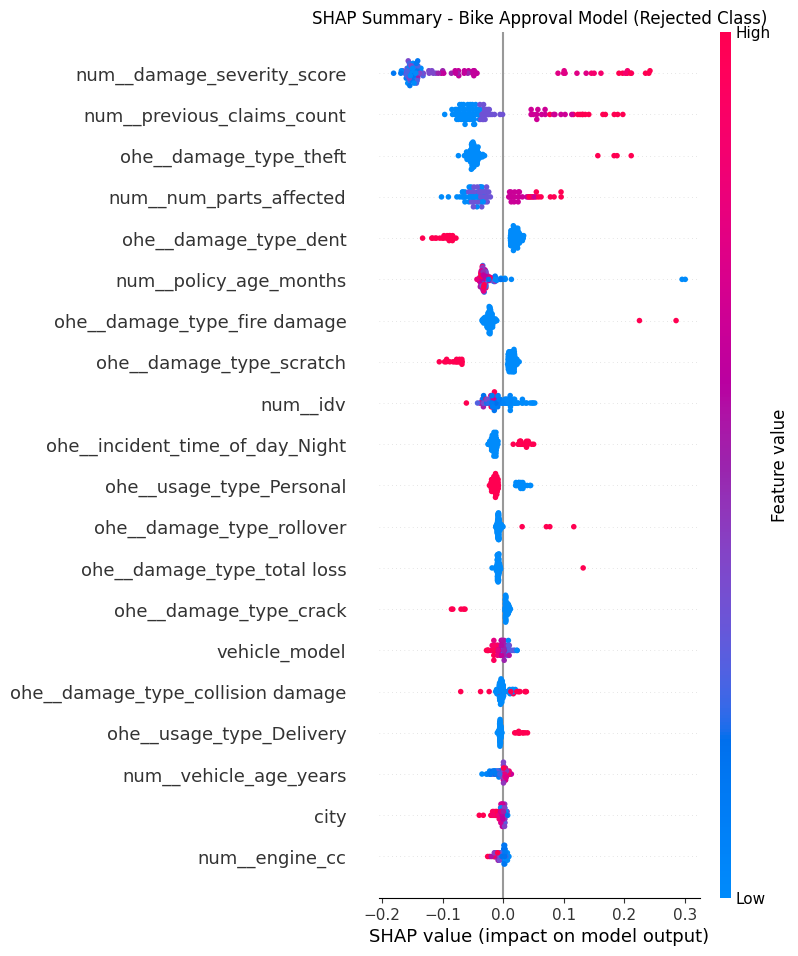

In [133]:
shap.summary_plot(
    shap_values_bike_approved[:, :, 0],  # class 0 = False/rejected
    X_sample_bike_approved,
    show=False
)
plt.title("SHAP Summary - Bike Approval Model (Rejected Class)")
plt.savefig(r"C:\projects\acko_insurance_ai_platform\reports\module3_shap_bike_approved.png", bbox_inches='tight', dpi=150)
plt.show()

In [134]:
explainer_car_approved = shap.TreeExplainer(rf_car_approved)
X_sample_car_approved = X_car_test_final_approved.sample(100, random_state=42)
shap_values_car_approved = explainer_car_approved.shap_values(X_sample_car_approved)

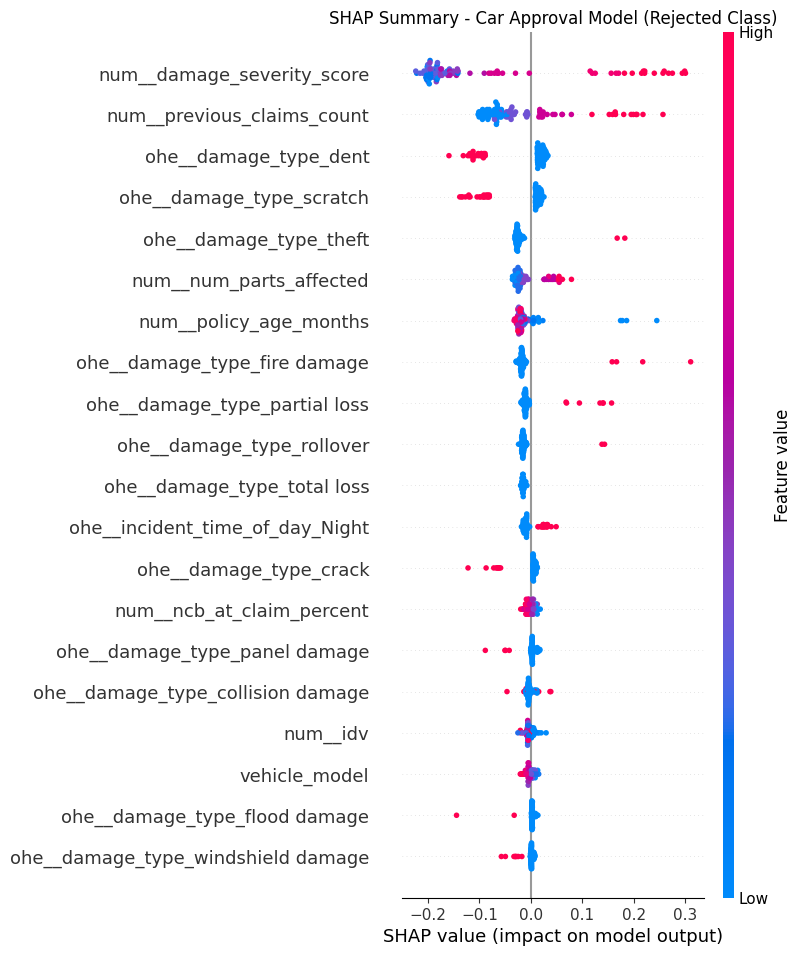

In [135]:
shap.summary_plot(
    shap_values_car_approved[:, :, 0],
    X_sample_car_approved,
    show=False
)
plt.title("SHAP Summary - Car Approval Model (Rejected Class)")
plt.savefig('../reports/module3_shap_car_approved.png', bbox_inches='tight', dpi=150)
plt.show()

In [137]:
# saving files

In [139]:
import joblib

In [141]:
# Models
joblib.dump(rf_bike_amount, '../models/claims_bike_amount_model.pkl')
joblib.dump(rf_car_amount, '../models/claims_car_amount_model.pkl')
joblib.dump(rf_bike_approved, '../models/claims_bike_approved_model.pkl')
joblib.dump(rf_car_approved, '../models/claims_car_approved_model.pkl')

# Preprocessors (ColumnTransformer - num + ohe)
joblib.dump(bike_preprocessor, '../models/claims_bike_preprocessor.pkl')
joblib.dump(car_preprocessor, '../models/claims_car_preprocessor.pkl')

# MultiLabelBinarizers (affected_parts)
joblib.dump(mlb_bike, '../models/claims_bike_mlb.pkl')
joblib.dump(mlb_car, '../models/claims_car_mlb.pkl')

# Target encoders - 4 total, one per vehicle-type/target combination
joblib.dump(target_encoder_bike_amount, '../models/claims_bike_target_encoder_amount.pkl')
joblib.dump(target_encoder_bike_approved, '../models/claims_bike_target_encoder_approved.pkl')
joblib.dump(target_encoder_car_amount, '../models/claims_car_target_encoder_amount.pkl')
joblib.dump(target_encoder_car_approved, '../models/claims_car_target_encoder_approved.pkl')

['../models/claims_car_target_encoder_approved.pkl']